# This notebook is for the visualization of 3D 2 color data acquired with a tetrapod PSF and fitted with Decode

In [1]:
from importlib import reload # to reload rq package
import copy
import time
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import numpy as np
import locan as lc
import pandas as pd
import napari
import os
import csv
import sys
import statistics
from copy import deepcopy
from scipy import spatial
import open3d as o3d
sys.path.append('E:\Receptor_Quantification\SMLM_analysis')
import ReceptorQ as rq
from pathlib import Path
np.float_ = np.float64
np.VisibleDeprecationWarning = np.exceptions.VisibleDeprecationWarning

<>:17: SyntaxWarning: invalid escape sequence '\R'
<>:17: SyntaxWarning: invalid escape sequence '\R'
C:\Users\ris82dr\AppData\Local\Temp\ipykernel_44332\2952173307.py:17: SyntaxWarning: invalid escape sequence '\R'
  sys.path.append('E:\Receptor_Quantification\SMLM_analysis')


In [2]:
lc.show_versions(system=False, dependencies=False, verbose=False)


Locan:
   version: 0.20.0

Python:
   version: 3.12.9


# 1. Preprocess data
## 1.1 Load data

In [2]:
loc_file_640 = r"F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\results_decode\250714_Ofa-647_C1q-568_WGA-405_3_dSTORM_640_combined_fit-250704.h5"
loc_raw_640 = lc.load_decode_file(loc_file_640)
z_matrix_640 = r"F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\results_decode\250714_Ofa-647_C1q-568_WGA-405_3_dSTORM_640_combined_z_offset.csv"

In [3]:
loc_file_532 = r"F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\results_decode\250714_Ofa-647_C1q-568_WGA-405_3_dSTORM_532_stack_combined_fit-250709.h5"
loc_raw_532 = lc.load_decode_file(loc_file_532)
z_matrix_532 = r"F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\results_decode\250714_Ofa-647_C1q-568_WGA-405_3_dSTORM_532_combined_z_offset.csv"
pixelsize = 111

In [4]:
offset_path = r"F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\results_decode\offset_matrix.npy"
transformation_path = r"F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\results_decode\alignment_matrix.npy"

## 1.2 Plot data

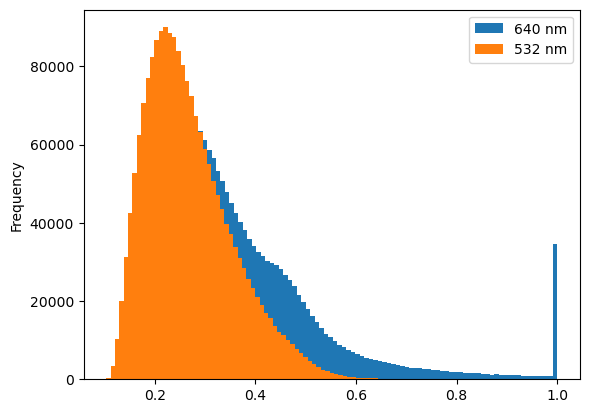

In [23]:
fig, ax = plt.subplots()

dat_640.data.prob.plot.hist(bins=100, ax=ax, label="640 nm")
dat_532.data.prob.plot.hist(bins=100, ax=ax, label="532 nm")

ax.legend()
plt.show()

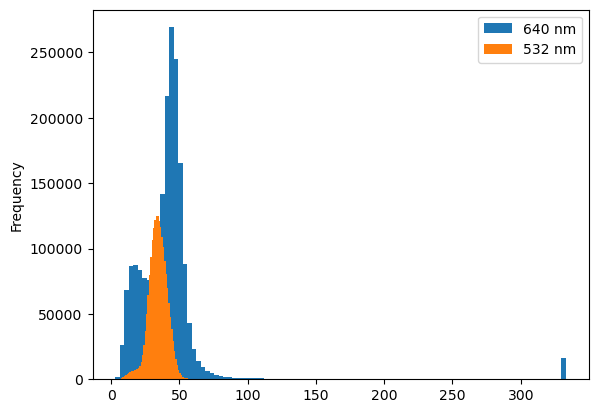

In [24]:
fig, ax = plt.subplots()

dat_640.data.x_sig.plot.hist(bins=100, ax=ax, label="640 nm")
dat_532.data.x_sig.plot.hist(bins=100, ax=ax, label="532 nm")

ax.legend()
plt.show()


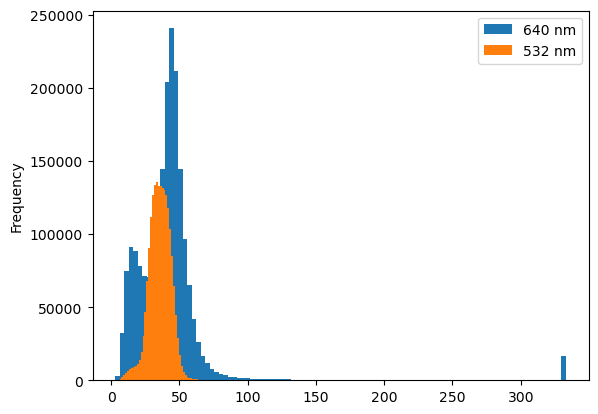

In [25]:
fig, ax = plt.subplots()

dat_640.data.y_sig.plot.hist(bins=100, ax=ax, label="640 nm")
dat_532.data.y_sig.plot.hist(bins=100, ax=ax, label="532 nm")

ax.legend()
plt.show()

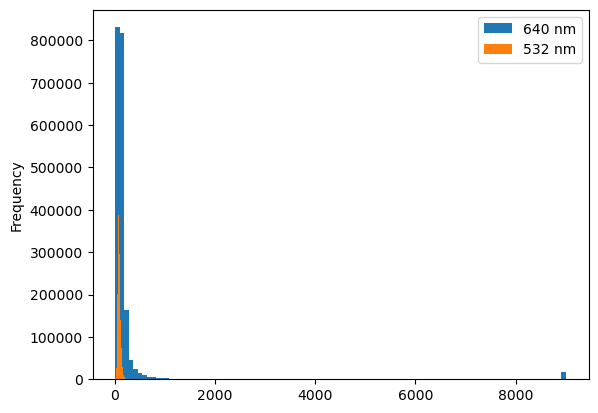

In [26]:
fig, ax = plt.subplots()

dat_640.data.z_sig.plot.hist(bins=100, ax=ax, label="640 nm")
dat_532.data.z_sig.plot.hist(bins=100, ax=ax, label="532 nm")

ax.legend()
plt.show()

## 1.2 filter data

In [27]:
# lateral coordinates in nm:

loc_raw_640.data.position_x = loc_raw_640.data.position_x*pixelsize
loc_raw_640.data.position_y = loc_raw_640.data.position_y*pixelsize
loc_raw_640.data.x_sig = loc_raw_640.data.x_sig*pixelsize
loc_raw_640.data.y_sig = loc_raw_640.data.y_sig*pixelsize

dat_640 = deepcopy(loc_raw_640)

In [28]:
# lateral coordinates in nm:

loc_raw_532.data.position_x = loc_raw_532.data.position_x*pixelsize
loc_raw_532.data.position_y = loc_raw_532.data.position_y*pixelsize
loc_raw_532.data.x_sig = loc_raw_532.data.x_sig*pixelsize
loc_raw_532.data.y_sig = loc_raw_532.data.y_sig*pixelsize

dat_532 = deepcopy(loc_raw_532)

In [31]:
dat_640 = lc.select_by_condition(dat_640, condition='0 < x_sig <22')
dat_640.reduce();

In [32]:
dat_640 = lc.select_by_condition(dat_640, condition='0 < y_sig < 22')
dat_640.reduce();

In [33]:
dat_640 = lc.select_by_condition(dat_640, condition='-2000 < position_z < 2000')
dat_640.reduce();

In [34]:
dat_640 = lc.select_by_condition(dat_640, condition='0.3 < prob < 1')
dat_640.reduce();

In [35]:
dat_640 = lc.select_by_condition(dat_640, condition='0 < z_sig < 45')
dat_640.reduce();

In [36]:
dat_532 = lc.select_by_condition(dat_532, condition='0 < x_sig < 22')

In [37]:
dat_532 = lc.select_by_condition(dat_532, condition='0 < y_sig < 22')
dat_532.reduce();

In [38]:
dat_532 = lc.select_by_condition(dat_532, condition='-2000 < position_z < 2000')
dat_532.reduce();

In [39]:
dat_532 = lc.select_by_condition(dat_532, condition='0.3 < prob < 1')
dat_532.reduce();

In [40]:
dat_532 = lc.select_by_condition(dat_532, condition='0 < z_sig < 45')
dat_532.reduce();

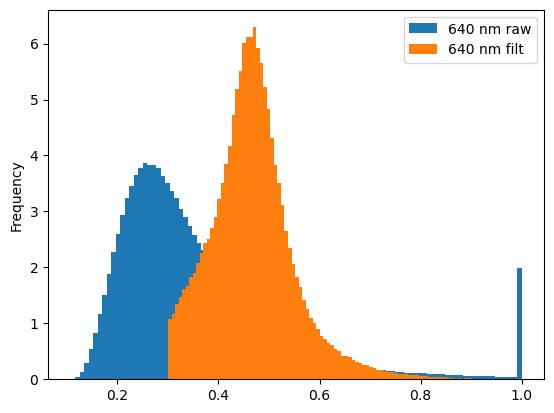

In [56]:
fig, ax = plt.subplots()

loc_raw_640.data.prob.plot.hist(bins=100, ax=ax, label="640 nm raw", density = True)
dat_640.data.prob.plot.hist(bins=100, ax=ax, label="640 nm filt", density = True)

ax.legend()
plt.show()

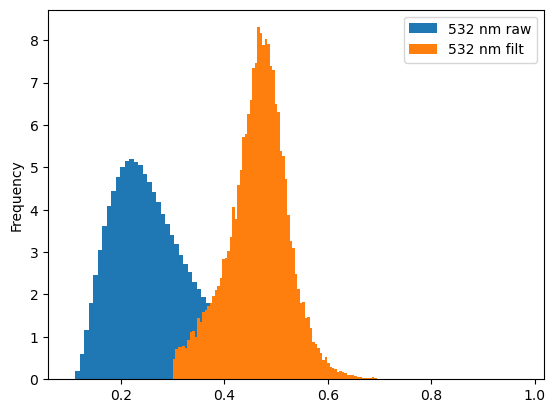

In [55]:
fig, ax = plt.subplots()

loc_raw_532.data.prob.plot.hist(bins=100, ax=ax, label="532 nm raw", density = True)
dat_532.data.prob.plot.hist(bins=100, ax=ax, label="532 nm filt", density = True)

ax.legend()
plt.show()

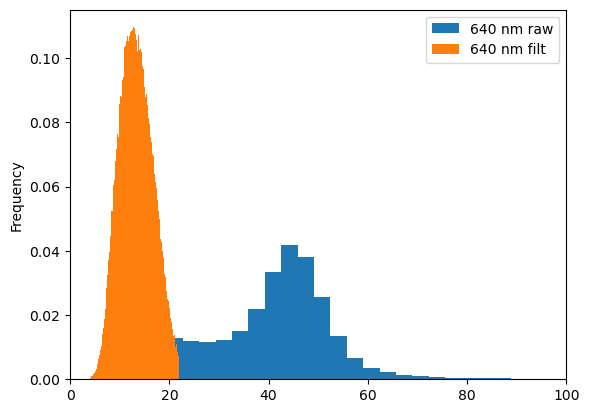

In [54]:
fig, ax = plt.subplots()

loc_raw_640.data.x_sig.plot.hist(bins=100, ax=ax, label="640 nm raw", xlim = (0, 100), density = True)
dat_640.data.x_sig.plot.hist(bins=100, ax=ax, label="640 nm filt", xlim = (0, 100), density = True)

ax.legend()
plt.show()

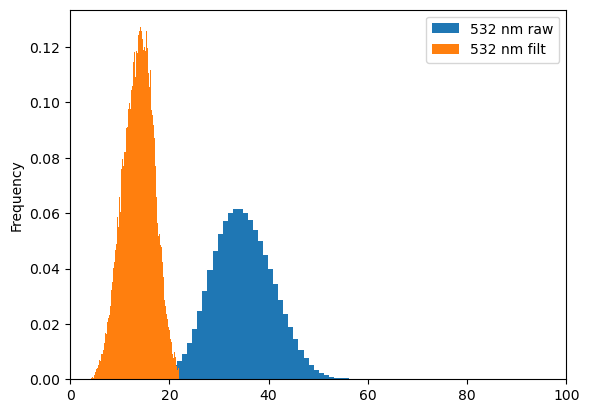

In [52]:
fig, ax = plt.subplots()

loc_raw_532.data.x_sig.plot.hist(bins=100, ax=ax, label="532 nm raw", xlim = (0, 100), density = True)
dat_532.data.x_sig.plot.hist(bins=100, ax=ax, label="532 nm filt", xlim = (0, 100), density = True)

ax.legend()
plt.show()

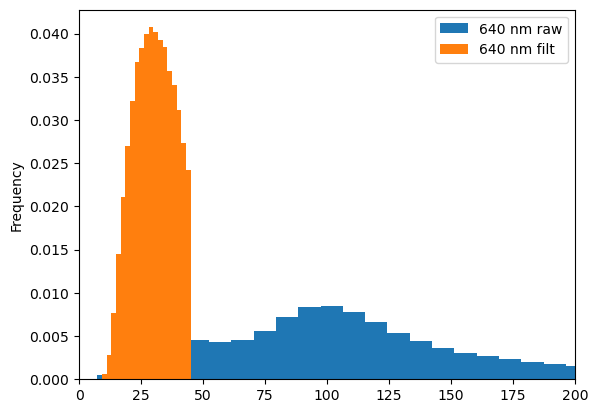

In [58]:
fig, ax = plt.subplots()

loc_raw_640.data.z_sig.plot.hist(bins=1000, ax=ax, label="640 nm raw", xlim = (0, 200), density = True)
dat_640.data.z_sig.plot.hist(bins=20, ax=ax, label="640 nm filt", xlim = (0, 200), density = True)

ax.legend()
plt.show()

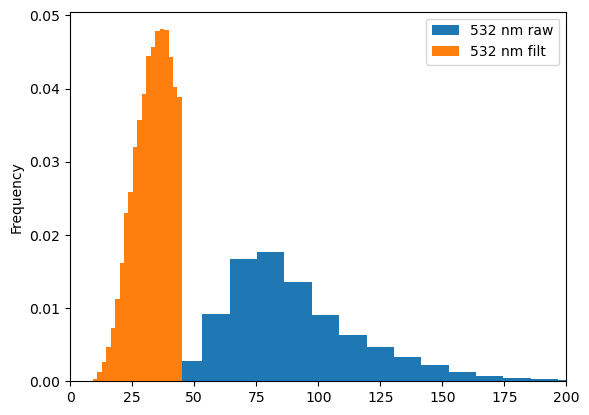

In [51]:
fig, ax = plt.subplots()

loc_raw_532.data.z_sig.plot.hist(bins=100, ax=ax, label="532 nm raw", xlim = (0, 200), density = True)
dat_532.data.z_sig.plot.hist(bins=20, ax=ax, label="532 nm filt", xlim = (0, 200), density = True)

ax.legend()
plt.show()

## 1.3 display data

In [59]:
loc_raw_532.data.describe()

,local_background,frame,original_index,intensity,phot_sig,prob,position_x,position_y,position_z,x_sig,y_sig,z_sig
count,1.985760e+06,1.985760e+06,1985760.0,1.985760e+06,1.985760e+06,1.985760e+06,1.985760e+06,1.985760e+06,1.985760e+06,1.985760e+06,1.985760e+06,1.985760e+06
mean,1.155695e+01,5.001207e+04,-1.0,1.035501e+03,2.045027e+02,2.683620e-01,1.398107e+04,1.390222e+04,-2.703452e+02,3.420480e+01,3.564175e+01,9.028532e+01
std,2.884109e+00,3.062218e+04,0.0,6.132867e+02,1.153550e+02,8.663785e-02,7.730185e+03,7.491591e+03,1.336361e+03,6.931054e+00,7.854099e+00,3.085811e+01
min,3.406996e+00,0.000000e+00,-1.0,2.242537e+02,6.455791e+01,1.032872e-01,4.541481e+00,-6.156410e+01,-2.620436e+03,4.216904e+00,3.359011e+00,9.091336e+00
25%,9.590574e+00,2.264400e+04,-1.0,6.141683e+02,1.119234e+02,2.035352e-01,7.572104e+03,8.020651e+03,-1.460171e+03,3.005377e+01,3.057578e+01,7.048257e+01
50%,1.155241e+01,4.913000e+04,-1.0,9.082005e+02,1.810817e+02,2.529374e-01,1.396352e+04,1.341925e+04,-2.720359e+02,3.429504e+01,3.579690e+01,8.438531e+01
75%,1.327005e+01,7.662600e+04,-1.0,1.280785e+03,2.588842e+02,3.187115e-01,2.023162e+04,2.008885e+04,7.808360e+02,3.873939e+01,4.114666e+01,1.045373e+02
max,6.780704e+01,1.049990e+05,-1.0,1.616446e+04,5.528623e+03,9.745172e-01,2.837623e+04,2.830259e+04,2.635172e+03,1.061321e+02,1.435264e+02,1.112639e+03


In [60]:
dat_532.data.describe()

,local_background,frame,original_index,intensity,phot_sig,prob,position_x,position_y,position_z,x_sig,y_sig,z_sig
count,36350.000000,36350.000000,36350.0,36350.000000,36350.000000,36350.000000,36350.000000,36350.000000,36350.000000,36350.000000,36350.000000,36350.000000
mean,13.217807,39165.198817,-1.0,2649.149902,275.712891,0.464543,17482.156250,16254.017578,-65.640839,13.746112,14.413764,33.045052
std,2.409445,29018.104612,0.0,1474.298706,122.438538,0.059396,3851.443359,4297.458008,914.213989,3.092518,3.975964,7.376665
min,5.277201,2.000000,-1.0,306.614502,83.554825,0.300029,178.122253,-42.395401,-1999.647461,4.216904,3.359011,9.091336
25%,11.550358,13652.000000,-1.0,1572.981506,178.621132,0.430788,15892.798096,12412.989258,-910.788132,11.588776,11.295983,27.817048
50%,13.044237,30855.500000,-1.0,2341.205688,257.880203,0.468724,18883.142578,17269.422852,264.207001,13.870412,14.357255,33.795994
75%,14.612707,57812.750000,-1.0,3407.695557,341.504494,0.501561,19964.065430,20443.093262,574.926331,15.948860,17.567851,39.017594
max,28.706186,104999.000000,-1.0,14611.994141,1536.308350,0.781473,28358.548828,28253.232422,1999.930908,21.997961,21.999813,44.999798


In [61]:
loc_raw_640.data.describe()

,local_background,frame,original_index,intensity,phot_sig,prob,position_x,position_y,position_z,x_sig,y_sig,z_sig
count,1.954204e+06,1.954204e+06,1954204.0,1.954204e+06,1.954204e+06,1.954204e+06,1.954204e+06,1.954204e+06,1.954204e+06,1.954204e+06,1.954204e+06,1.954204e+06
mean,7.090380e+01,3.544695e+04,-1.0,4.218303e+03,1.904903e+03,3.584779e-01,1.697851e+04,1.478236e+04,-2.522568e+02,4.182281e+01,4.268776e+01,2.277412e+02
std,2.868794e+01,3.206901e+04,0.0,4.184666e+03,8.437144e+03,1.616143e-01,6.310268e+03,6.777750e+03,1.245479e+03,3.341710e+01,3.463555e+01,8.954291e+02
min,6.261712e-01,0.000000e+00,-1.0,3.355097e+02,1.451861e+02,1.074401e-01,2.717060e+00,9.091780e+00,-2.614836e+03,2.907435e+00,2.883897e+00,7.381460e+00
25%,6.122294e+01,6.908000e+03,-1.0,1.727584e+03,3.614804e+02,2.495528e-01,1.295397e+04,9.660038e+03,-1.108528e+03,2.853485e+01,2.835063e+01,7.322968e+01
50%,6.605522e+01,2.423600e+04,-1.0,2.522875e+03,4.965949e+02,3.179365e-01,1.817887e+04,1.444027e+04,-4.017315e+02,4.166475e+01,4.166228e+01,1.061159e+02
75%,7.223489e+01,6.020000e+04,-1.0,5.186203e+03,8.901471e+02,4.237601e-01,2.099126e+04,2.042687e+04,5.023274e+02,4.782236e+01,4.873483e+01,1.507012e+02
max,3.869972e+02,1.049990e+05,-1.0,2.697630e+04,8.095588e+04,1.000000e+00,2.837954e+04,2.837141e+04,2.609798e+03,3.331110e+02,3.331110e+02,9.003000e+03


In [62]:
dat_640.data.describe()

,local_background,frame,original_index,intensity,phot_sig,prob,position_x,position_y,position_z,x_sig,y_sig,z_sig
count,186562.000000,186562.000000,186562.0,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000
mean,65.551170,38469.294626,-1.0,6574.904297,646.665344,0.467635,15264.939453,15582.699219,-143.311707,13.267252,13.181259,30.102062
std,6.917309,28734.338745,0.0,3088.792725,372.783478,0.084043,4028.385010,3980.585449,949.755005,3.384194,3.761248,8.051723
min,30.351854,0.000000,-1.0,455.746399,171.738754,0.300001,1678.221069,1434.680786,-1999.981812,2.907435,2.883897,7.381460
25%,60.881380,13283.250000,-1.0,4604.183472,411.985229,0.415724,11914.453613,12196.423584,-953.174484,10.759903,10.325512,23.827493
50%,64.788185,30596.000000,-1.0,6320.587402,535.865631,0.463408,16012.685059,16160.222168,-50.842823,13.109357,12.844027,30.157734
75%,69.515968,57549.500000,-1.0,8182.755371,765.366837,0.509090,18915.157715,19219.020508,618.459656,15.661099,15.911740,36.603255
max,146.698761,104991.000000,-1.0,22761.593750,6029.586914,0.998795,28357.777344,28352.871094,1999.956299,21.998987,21.999985,44.999218


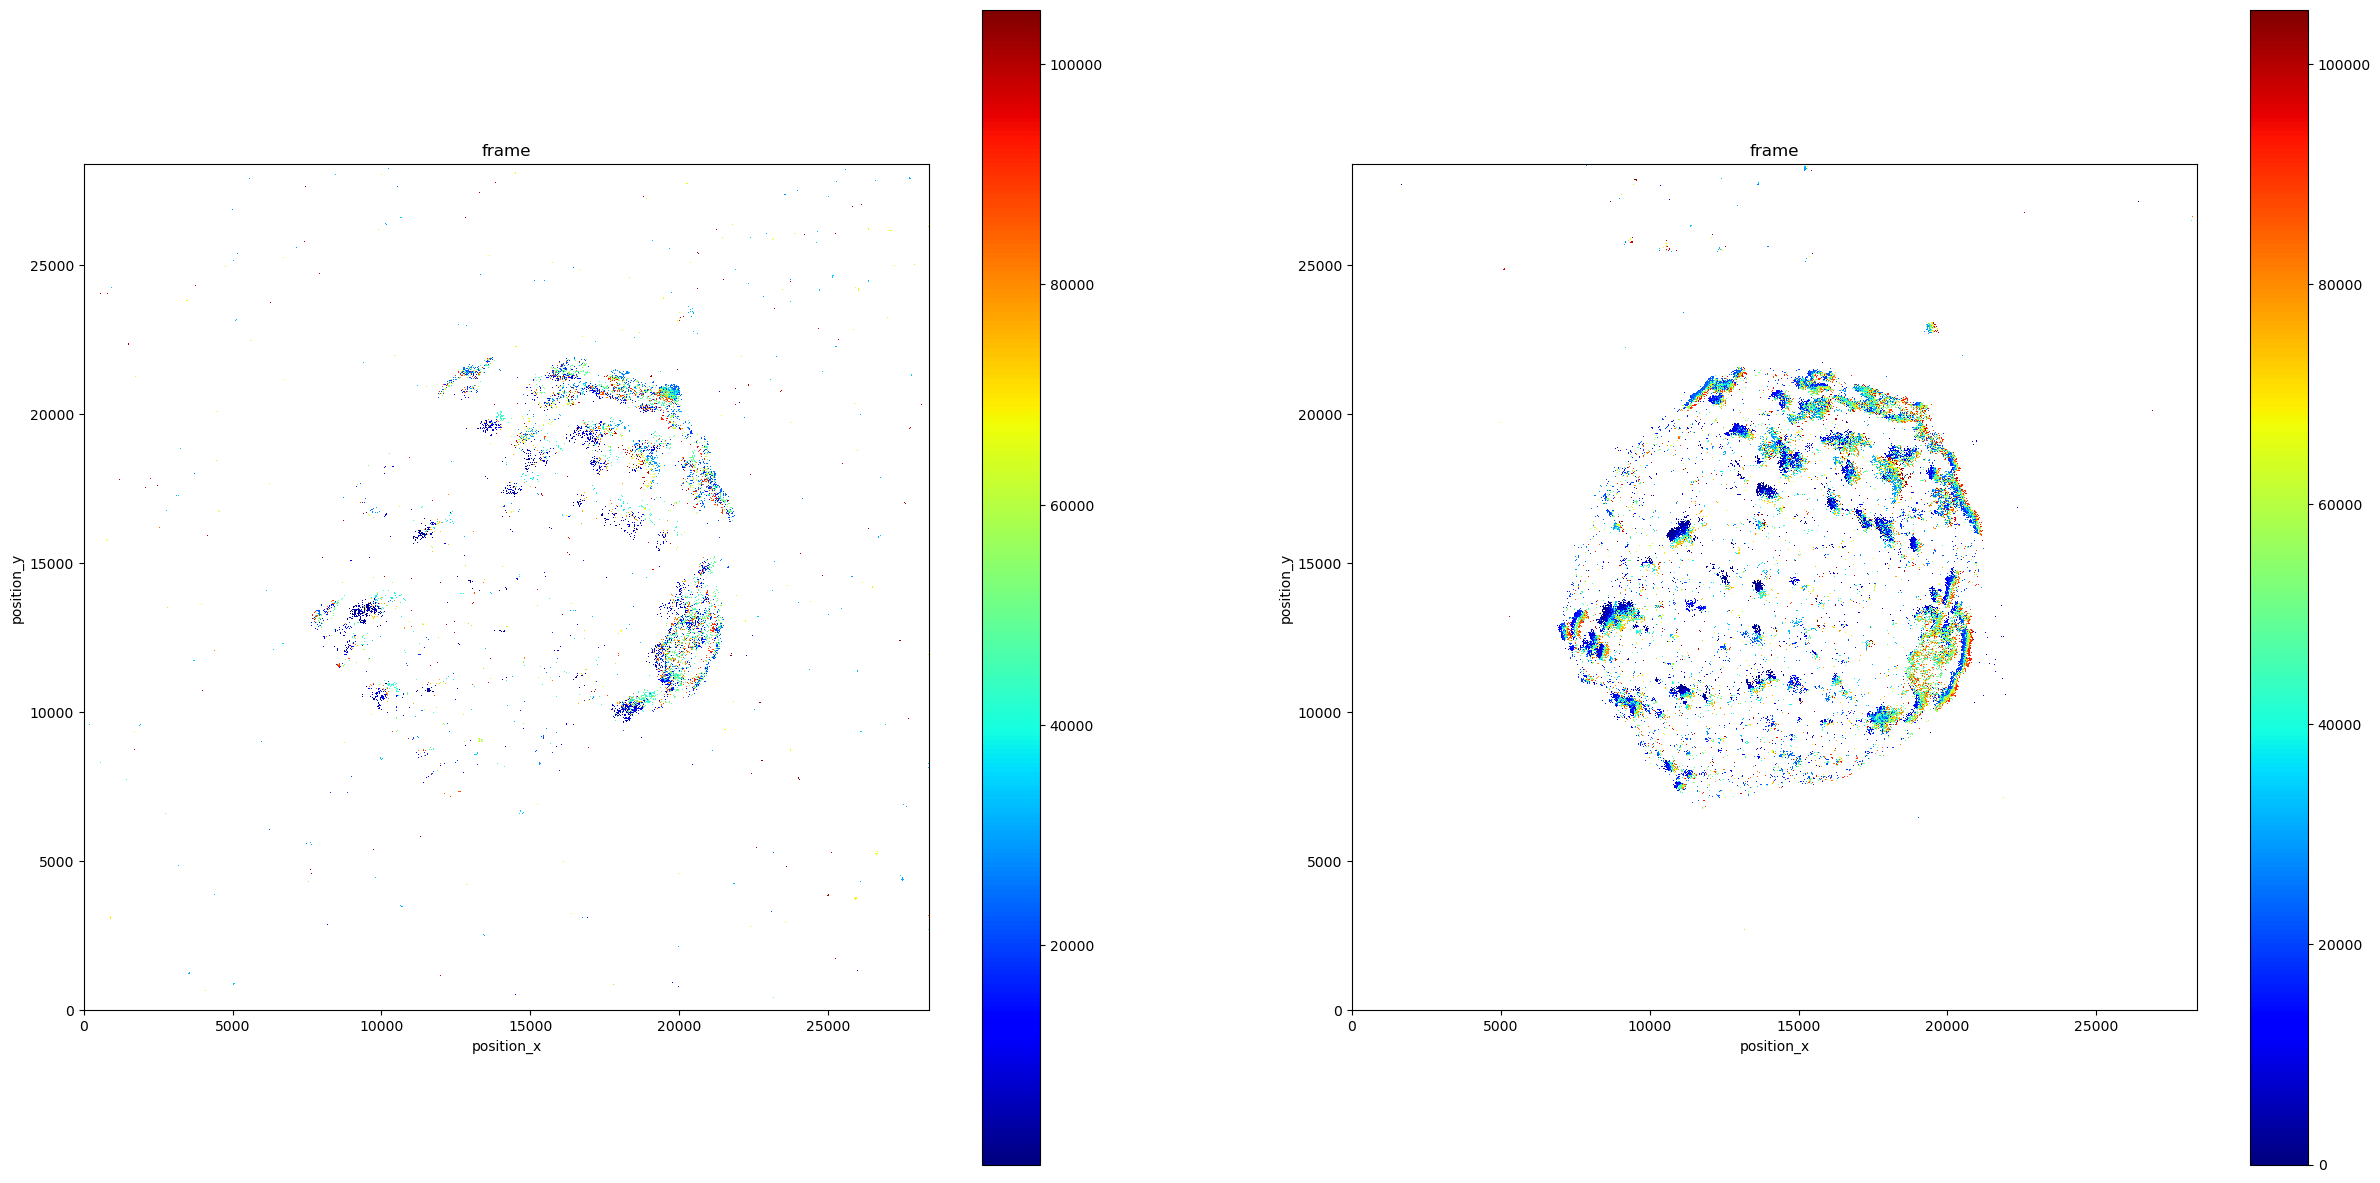

In [63]:
# plt in 2D
plt.style.use('default')
fig, axes = plt.subplots(1, 2, figsize=(30, 15))
lc.render_2d_mpl(dat_532, loc_properties=['position_x', 'position_y'], ax= axes[0], bin_size=(20, 20),  other_property='frame', cmap='jet', bin_range=(0, 28416));
lc.render_2d_mpl(dat_640, loc_properties=['position_x', 'position_y'], ax= axes[1], bin_size=(20, 20), other_property='frame', cmap = 'jet', bin_range=(0, 28416));

## 2 Reconstruct Z-Stack
### 2.1 Load Z-matrix

In [64]:
csv_list_532 = []
with open(z_matrix_532, 'r') as file:
    csvfile = csv.reader(file)
    for line in csvfile:
        csv_list_532.append(line)
shift_values_532 = list(map(float, csv_list_532[1]))

csv_list_640 = []
with open(z_matrix_640, 'r') as file:
    csvfile = csv.reader(file)
    for line in csvfile:
        csv_list_640.append(line)
shift_values_640 = list(map(float, csv_list_640[1]))

In [65]:
# calculate mean z shift:
stack_size = int(len(shift_values_640)/3)
c1_640 = shift_values_640[0:stack_size]
c2_640 = shift_values_640[stack_size:stack_size*2]
c3_640 = shift_values_640[stack_size*2:stack_size*3]
c1_532 = shift_values_532[0:stack_size]
c2_532 = shift_values_532[stack_size:stack_size*2]
c3_532 = shift_values_532[stack_size*2:stack_size*3]
shift_mean = [(u + v + w + x + y + z)/6 for u, v, w, x, y, z in zip(c1_640, c2_640, c3_640, c1_532, c2_532, c3_532)]
shift_mean_values = shift_mean*3

### 2.2 Correct Z-position 640nm

In [66]:
# correct Z-positions:
start = 0
stop = 5000
corrected_z = pd.Series()
for shift in shift_mean_values:
    old_z_pos = lc.select_by_condition(dat_640, condition=f'{start} <= frame < {stop}').data.position_z
    new_z_pos = -old_z_pos + shift # switch algebraic sign
    corrected_z = pd.concat([corrected_z, new_z_pos])
    start += 5000
    stop += 5000

In [67]:
dat_640_z_cor = deepcopy(dat_640)
dat_640_z_cor.data.position_z = corrected_z
dat_640_z_cor.data.describe()

,local_background,frame,original_index,intensity,phot_sig,prob,position_x,position_y,x_sig,y_sig,z_sig
count,186562.000000,186562.000000,186562.0,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000
mean,65.551170,38469.294626,-1.0,6574.904297,646.665344,0.467635,15264.939453,15582.699219,13.267252,13.181259,30.102062
std,6.917309,28734.338745,0.0,3088.792725,372.783478,0.084043,4028.385010,3980.585449,3.384194,3.761248,8.051723
min,30.351854,0.000000,-1.0,455.746399,171.738754,0.300001,1678.221069,1434.680786,2.907435,2.883897,7.381460
25%,60.881380,13283.250000,-1.0,4604.183472,411.985229,0.415724,11914.453613,12196.423584,10.759903,10.325512,23.827493
50%,64.788185,30596.000000,-1.0,6320.587402,535.865631,0.463408,16012.685059,16160.222168,13.109357,12.844027,30.157734
75%,69.515968,57549.500000,-1.0,8182.755371,765.366837,0.509090,18915.157715,19219.020508,15.661099,15.911740,36.603255
max,146.698761,104991.000000,-1.0,22761.593750,6029.586914,0.998795,28357.777344,28352.871094,21.998987,21.999985,44.999218


### 2.3 Correct Z-position 532nm

In [68]:
# correct Z-positions:
start = 0
stop = 5000
corrected_z = pd.Series()
for shift in shift_mean_values:
    old_z_pos = lc.select_by_condition(dat_532, condition=f'{start} <= frame < {stop}').data.position_z
    new_z_pos = -old_z_pos + shift # switch algebraic sign
    corrected_z = pd.concat([corrected_z, new_z_pos])
    start += 5000
    stop += 5000

In [69]:
dat_532_z_cor = deepcopy(dat_532)
dat_532_z_cor.data.position_z = corrected_z
dat_532_z_cor.data.describe()

,local_background,frame,original_index,intensity,phot_sig,prob,position_x,position_y,x_sig,y_sig,z_sig
count,36350.000000,36350.000000,36350.0,36350.000000,36350.000000,36350.000000,36350.000000,36350.000000,36350.000000,36350.000000,36350.000000
mean,13.217807,39165.198817,-1.0,2649.149902,275.712891,0.464543,17482.156250,16254.017578,13.746112,14.413764,33.045052
std,2.409445,29018.104612,0.0,1474.298706,122.438538,0.059396,3851.443359,4297.458008,3.092518,3.975964,7.376665
min,5.277201,2.000000,-1.0,306.614502,83.554825,0.300029,178.122253,-42.395401,4.216904,3.359011,9.091336
25%,11.550358,13652.000000,-1.0,1572.981506,178.621132,0.430788,15892.798096,12412.989258,11.588776,11.295983,27.817048
50%,13.044237,30855.500000,-1.0,2341.205688,257.880203,0.468724,18883.142578,17269.422852,13.870412,14.357255,33.795994
75%,14.612707,57812.750000,-1.0,3407.695557,341.504494,0.501561,19964.065430,20443.093262,15.948860,17.567851,39.017594
max,28.706186,104999.000000,-1.0,14611.994141,1536.308350,0.781473,28358.548828,28253.232422,21.997961,21.999813,44.999798


## 2.4 Correct chromatic abberation

In [70]:
offset_matrix = np.load(offset_path)
transformation_matrix = np.load(transformation_path)

In [71]:
sample_coordinates_1 = dat_532_z_cor.coordinates
corrected_sample_coordinates_1 = np.matmul(sample_coordinates_1, transformation_matrix) + offset_matrix
corrected_sample_coordinates_1
x_coordinates = corrected_sample_coordinates_1[:, 0].tolist()
y_coordinates = corrected_sample_coordinates_1[:, 1].tolist()
z_coordinates = corrected_sample_coordinates_1[:, 2].tolist()
dat_532_z_cor_al = deepcopy(dat_532_z_cor)
dat_532_z_cor_al = dat_532_z_cor_al.data.drop(["position_x", "position_y", "position_z"], axis=1)
dat_532_z_cor_al.insert(loc=0, column="position_x", value=x_coordinates)
dat_532_z_cor_al.insert(loc=1, column="position_y", value=y_coordinates)
dat_532_z_cor_al.insert(loc=2, column="position_z", value=z_coordinates)
dat_532_z_cor_al = lc.LocData.from_dataframe(dataframe=dat_532_z_cor_al)

## 2.5 Visualize reconstruction and chromatic alignment

In [72]:
viewer = napari.Viewer(ndisplay=3)

In [73]:
# visualize 640 nm depth PSF with probability colorcode
prob_width = 90 # range of point size

coordinates = pd.DataFrame(
    {
        'position_z': dat_640_z_cor.data.position_z,
        'position_x': dat_640_z_cor.data.position_x,
        'position_y': dat_640_z_cor.data.position_y,

    })

colors = dat_640_z_cor.data.position_z.to_numpy()
colors_norm = (colors-np.min(colors))/(np.max(colors)-np.min(colors))

prob = dat_640_z_cor.data.x_sig.to_numpy()#*111
prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1

point_features = {
    'z_value': colors_norm,
    'prob': (1/prob).tolist(),
}

points = coordinates.to_numpy()

viewer.add_points(points, symbol='o', features=point_features, face_color='prob', face_colormap= 'magenta', border_color='prob', border_colormap='magenta', size=prob_norm, name= '640 nm prob', blending='additive')

<Points layer '640 nm prob' at 0x1b08cd64590>

In [74]:
# visualize 532 nm chromatic abberation corrected
coordinates = pd.DataFrame(
    {
        'position_z': dat_532_z_cor.data.position_z,
        'position_x': dat_532_z_cor.data.position_x,
        'position_y': dat_532_z_cor.data.position_y,

    })

colors = dat_532_z_cor.data.frame.to_numpy()
colors_norm = (colors-np.min(colors))/(np.max(colors)-np.min(colors))

prob = dat_532_z_cor.data.x_sig.to_numpy()
prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1


point_features = {
    'z_value': colors_norm,
    'prob': (1/prob).tolist(),
}

points = coordinates.to_numpy()
viewer.add_points(points, symbol='o', features=point_features, face_color='prob', face_colormap= 'green', border_color='prob', border_colormap='green', size=prob_norm, name= '532 nm prob', blending='additive')

<Points layer '532 nm prob' at 0x1b087c2dd10>

In [75]:
# visualize 532 nm
coordinates = pd.DataFrame(
    {
        'position_z': dat_532_z_cor_al.data.position_z,
        'position_x': dat_532_z_cor_al.data.position_x,
        'position_y': dat_532_z_cor_al.data.position_y,

    })

colors = dat_532_z_cor_al.data.frame.to_numpy()
colors_norm = (colors-np.min(colors))/(np.max(colors)-np.min(colors))

prob = dat_532_z_cor_al.data.x_sig.to_numpy()
prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1


point_features = {
    'z_value': colors_norm,
    'prob': (1/prob).tolist(),
}

points = coordinates.to_numpy()
viewer.add_points(points, symbol='o', features=point_features, face_color='prob', face_colormap= 'green', border_color='prob', border_colormap='green', size=prob_norm, name= '532 nm prob al', blending='additive')

<Points layer '532 nm prob al' at 0x1b0804e39d0>

# 3. Drift and offset correction 640 nm
## 3.1 Correct lateral drift with AIM 640 nm

In [76]:
step_size = 5_000
stack_rounds = 3
drift_chunks = []
x_mean_drift = []
y_mean_drift = []
frames_mean_drift = []
slices_p_round = int(len(shift_values_640)/stack_rounds) # calculate number of slices for a whole stack
drift_cor_locs = deepcopy(dat_640_z_cor)
for round in range(0, stack_rounds):
    print(f"round {round}")
    start_frame = 0 + (round*step_size) * slices_p_round
    stop_frame = step_size*2 + (round*step_size) * slices_p_round
    for slice in range(0, slices_p_round-1):
        print(f"slices {slice}")
        locs_slice = lc.select_by_condition(drift_cor_locs, condition=f'{start_frame} <= frame < {stop_frame}')
        locs_slice.reduce();
        locs_slice = lc.select_by_condition(locs_slice, condition=f'{shift_values_640[slice+(slices_p_round*round)+1]} < position_z < {shift_values_640[slice+(slices_p_round*round)]}')
        locs_slice.reduce();
        locs_slice_cor, drift = rq.estimate_drift_aim(locs_slice, segmentation=600, n_frames = 2*step_size, intersect_d = 13/111, roi_r=40/111, roi_r_z= 40/111, first_frame=start_frame, thirdD= False)
        #print(locs_slice.data.describe())
        print(start_frame, stop_frame)

        print(round)
        print(slice)
        if round != 0 or slice != 0: # calculate offset between old frame and new frame to align drift chunks to each other
            x_mean_new = drift['x'][:step_size].mean()
            y_mean_new = drift['y'][:step_size].mean()
            x_offset = x_mean_new - x_mean_old
            y_offset = y_mean_new - y_mean_old
            print(x_offset)
            drift['x'] = drift['x'] - x_offset
            drift['y'] = drift['y'] - y_offset

        drift_chunks.append(drift)

        if slice == 0: # for the first slice append first half of drift chunk to the mean values
            x_mean_drift.extend(drift['x'][:step_size].tolist())
            y_mean_drift.extend(drift['y'][:step_size].tolist())
            frames_mean_drift.extend(drift['frame'][:step_size].tolist())
        elif slice == (slices_p_round-2): # for the last frame of one round calculate mean and append last half of drift chunk
            #append mean of first half of chunk:
            x_mean_drift.extend(((last_drift['x'] + drift['x'][:step_size])/2).tolist())
            y_mean_drift.extend(((last_drift['y'] + drift['y'][:step_size])/2).tolist())
            frames_mean_drift.extend(drift['frame'][:step_size].tolist())
            #append last half of chunk:
            x_mean_drift.extend(drift['x'][step_size:].tolist())
            y_mean_drift.extend(drift['y'][step_size:].tolist())
            frames_mean_drift.extend(drift['frame'][step_size:].tolist())
        else: # for all other frames calculate mean of first half and append
            x_mean_drift.extend(((last_drift['x'] + drift['x'][:step_size])/2).tolist())
            y_mean_drift.extend(((last_drift['y'] + drift['y'][:step_size])/2).tolist())
            frames_mean_drift.extend(drift['frame'][:step_size].tolist())

        last_drift = drift[step_size:]


        x_mean_old = drift['x'][5000:].mean()
        y_mean_old = drift['y'][5000:].mean()
        start_frame +=step_size
        stop_frame += step_size
mean_drift = np.rec.array((np.array(x_mean_drift), np.array(y_mean_drift), np.array(frames_mean_drift)),
                                  dtype=[("x", "f"), ("y", "f"), ("frame", "f")]
                                  )

round 0
slices 0


Undrifting (2/2): 100%|██████████| 17/17 [00:00<00:00, 90.49segment/s]


0 10000
0
0
slices 1


Undrifting (2/2): 100%|██████████| 17/17 [00:00<00:00, 73.39segment/s] 


5000 15000
0
1
-110.21977
slices 2


...

85000 95000
2
3
-252.39456
slices 4


Undrifting (2/2): 100%|██████████| 17/17 [00:00<00:00, 105.17segment/s]


90000 100000
2
4
-336.1224
slices 5


Undrifting (2/2): 100%|██████████| 17/17 [00:00<00:00, 104.70segment/s]

95000 105000
2
5
-256.42258


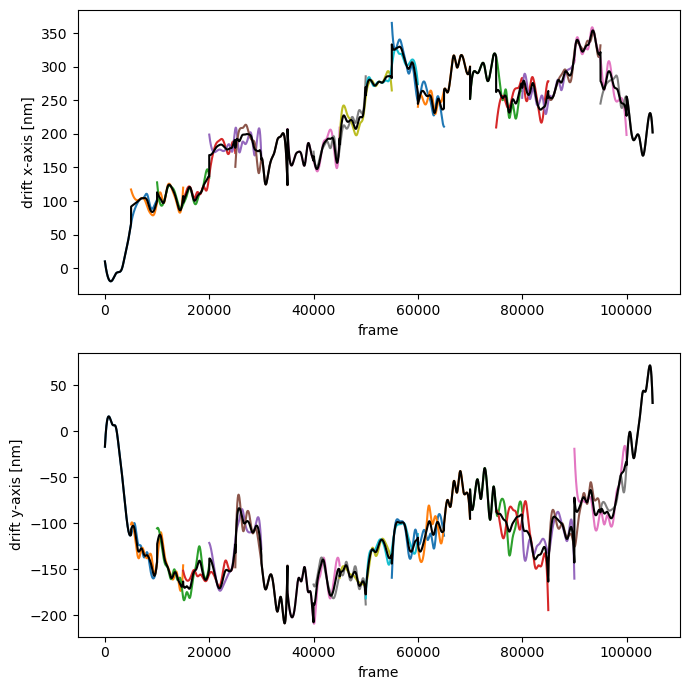

In [97]:
fig, axs = plt.subplots(nrows =2, ncols = 1, figsize = (7,7))
for chunk in drift_chunks:
    axs[0].plot(chunk['frame'], chunk['x'])
    axs[1].plot(chunk['frame'], chunk['y'])
axs[0].plot(mean_drift['frame'], mean_drift['x'], color = 'black')
axs[0].set_xlabel('frame')
axs[0].set_ylabel('drift x-axis [nm]')
axs[1].plot(mean_drift['frame'], mean_drift['y'], color = 'black')
axs[1].set_xlabel('frame')
axs[1].set_ylabel('drift y-axis [nm]')
fig.tight_layout()

In [103]:
# Correct x/y drift relative to the last frame; preserve z coordinates
dat_640_xyz_cor = deepcopy(dat_640_z_cor)

drift_frames = np.column_stack([
    mean_drift["x"],
    mean_drift["y"],
]).astype(float)

frames = dat_640_xyz_cor.data["frame"].to_numpy(dtype=int)

for axis, column in enumerate(["position_x", "position_y"]):
    coordinates = dat_640_z_cor.data[column].to_numpy(dtype=float)

    dat_640_xyz_cor.data[column] = (
        coordinates
        - drift_frames[frames, axis]
        + drift_frames[-1, axis]
    )

## 3.2 Correct drift with AIM and ICP combined:

In [107]:
step_size = 5_000
stack_rounds = 3
slices_p_round = int(len(shift_values_640)/stack_rounds) # calculate number of slices for a whole stack
first_slice = lc.select_by_condition(dat_640_xyz_cor, condition=f'{0} <= frame < {slices_p_round*step_size}')
first_slice.reduce();
second_slice = lc.select_by_condition(dat_640_xyz_cor, condition=f'{slices_p_round*step_size} <= frame < {slices_p_round*step_size*2}')
second_slice.reduce();
third_slice = lc.select_by_condition(dat_640_xyz_cor, condition=f'{slices_p_round*step_size*2} <= frame < {slices_p_round*step_size*3}')
third_slice.reduce();

first_slice_cor, matrix = rq.align_locdata_ransac_icp(moving_ld = first_slice, fixed_ld = second_slice, align_z = False)
first_cor_second_uncor = lc.LocData.concat([first_slice_cor, second_slice])

first_second_cor, matrix = rq.align_locdata_ransac_icp(moving_ld = first_cor_second_uncor, fixed_ld = third_slice, align_z = False)
icp_cor = lc.LocData.concat([first_second_cor, third_slice])

pc1 (moving) shape: (97474, 3)
pc2 (fixed) shape: (53387, 3)
align_z=False: using z=0 projection for registration.
Bounding box diagonal (target, registration coords): 37517.426
Centroid distance before registration (registration coords): 973.6229

=== Global registration: RANSAC (Open3D) ===
RANSAC runtime: 0.274 s
RANSAC fitness: 0.0 inlier RMSE: 0.0
RANSAC transformation:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
RANSAC looks unreliable (low fitness, large translation, or high inlier RMSE).
Using identity as initial transform for ICP.

=== Multi-scale ICP refinement ===
ICP max correspondence distances (coarse → fine): [100.0, 60.0, 30.0]

--- ICP stage 1 with max_dist = 100.00 ---
ICP stage 1 runtime: 0.747 s
ICP stage 1 fitness: 0.9438, inlier RMSE: 24.3891

--- ICP stage 2 with max_dist = 60.00 ---
ICP stage 2 runtime: 0.530 s
ICP stage 2 fitness: 0.9038, inlier RMSE: 18.7708

--- ICP stage 3 with max_dist = 30.00 ---
ICP stage 3 runtime: 0.715 s
ICP stage 3 f

## 3.3 Correct drift with ICP

In [108]:
step_size = 5_000
stack_rounds = 3
slices_p_round = int(len(shift_values_640)/stack_rounds) # calculate number of slices for a whole stack
first_slice = lc.select_by_condition(dat_640_z_cor, condition=f'{0} <= frame < {slices_p_round*step_size}')
first_slice.reduce();
second_slice = lc.select_by_condition(dat_640_z_cor, condition=f'{slices_p_round*step_size} <= frame < {slices_p_round*step_size*2}')
second_slice.reduce();
third_slice = lc.select_by_condition(dat_640_z_cor, condition=f'{slices_p_round*step_size*2} <= frame < {slices_p_round*step_size*3}')
third_slice.reduce();

first_slice_cor, matrix = rq.align_locdata_ransac_icp(moving_ld = first_slice, fixed_ld = second_slice, align_z = False)
first_cor_second_uncor = lc.LocData.concat([first_slice_cor, second_slice])

first_second_cor, matrix = rq.align_locdata_ransac_icp(moving_ld = first_cor_second_uncor, fixed_ld = third_slice, align_z = False)
icp_cor_only = lc.LocData.concat([first_second_cor, third_slice])

pc1 (moving) shape: (97474, 3)
pc2 (fixed) shape: (53387, 3)
align_z=False: using z=0 projection for registration.
Bounding box diagonal (target, registration coords): 37504.617
Centroid distance before registration (registration coords): 1095.7334

=== Global registration: RANSAC (Open3D) ===
RANSAC runtime: 0.321 s
RANSAC fitness: 0.9986252744321563 inlier RMSE: 83.66118312139443
RANSAC transformation:
 [[ 9.99993773e-01  3.52891586e-03  0.00000000e+00 -1.41703760e+02]
 [-3.52891586e-03  9.99993773e-01  0.00000000e+00  9.15224813e+01]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]

=== Multi-scale ICP refinement ===
ICP max correspondence distances (coarse → fine): [100.0, 60.0, 30.0]

--- ICP stage 1 with max_dist = 100.00 ---
ICP stage 1 runtime: 0.773 s
ICP stage 1 fitness: 0.9317, inlier RMSE: 27.1185

--- ICP stage 2 with max_dist = 60.00 ---
ICP stage 2 runtime: 0.744 s
ICP stage 2 fitness: 

## 3.4 Display drift corrected images

Text(0.5, 1.0, 'ICP correction only')

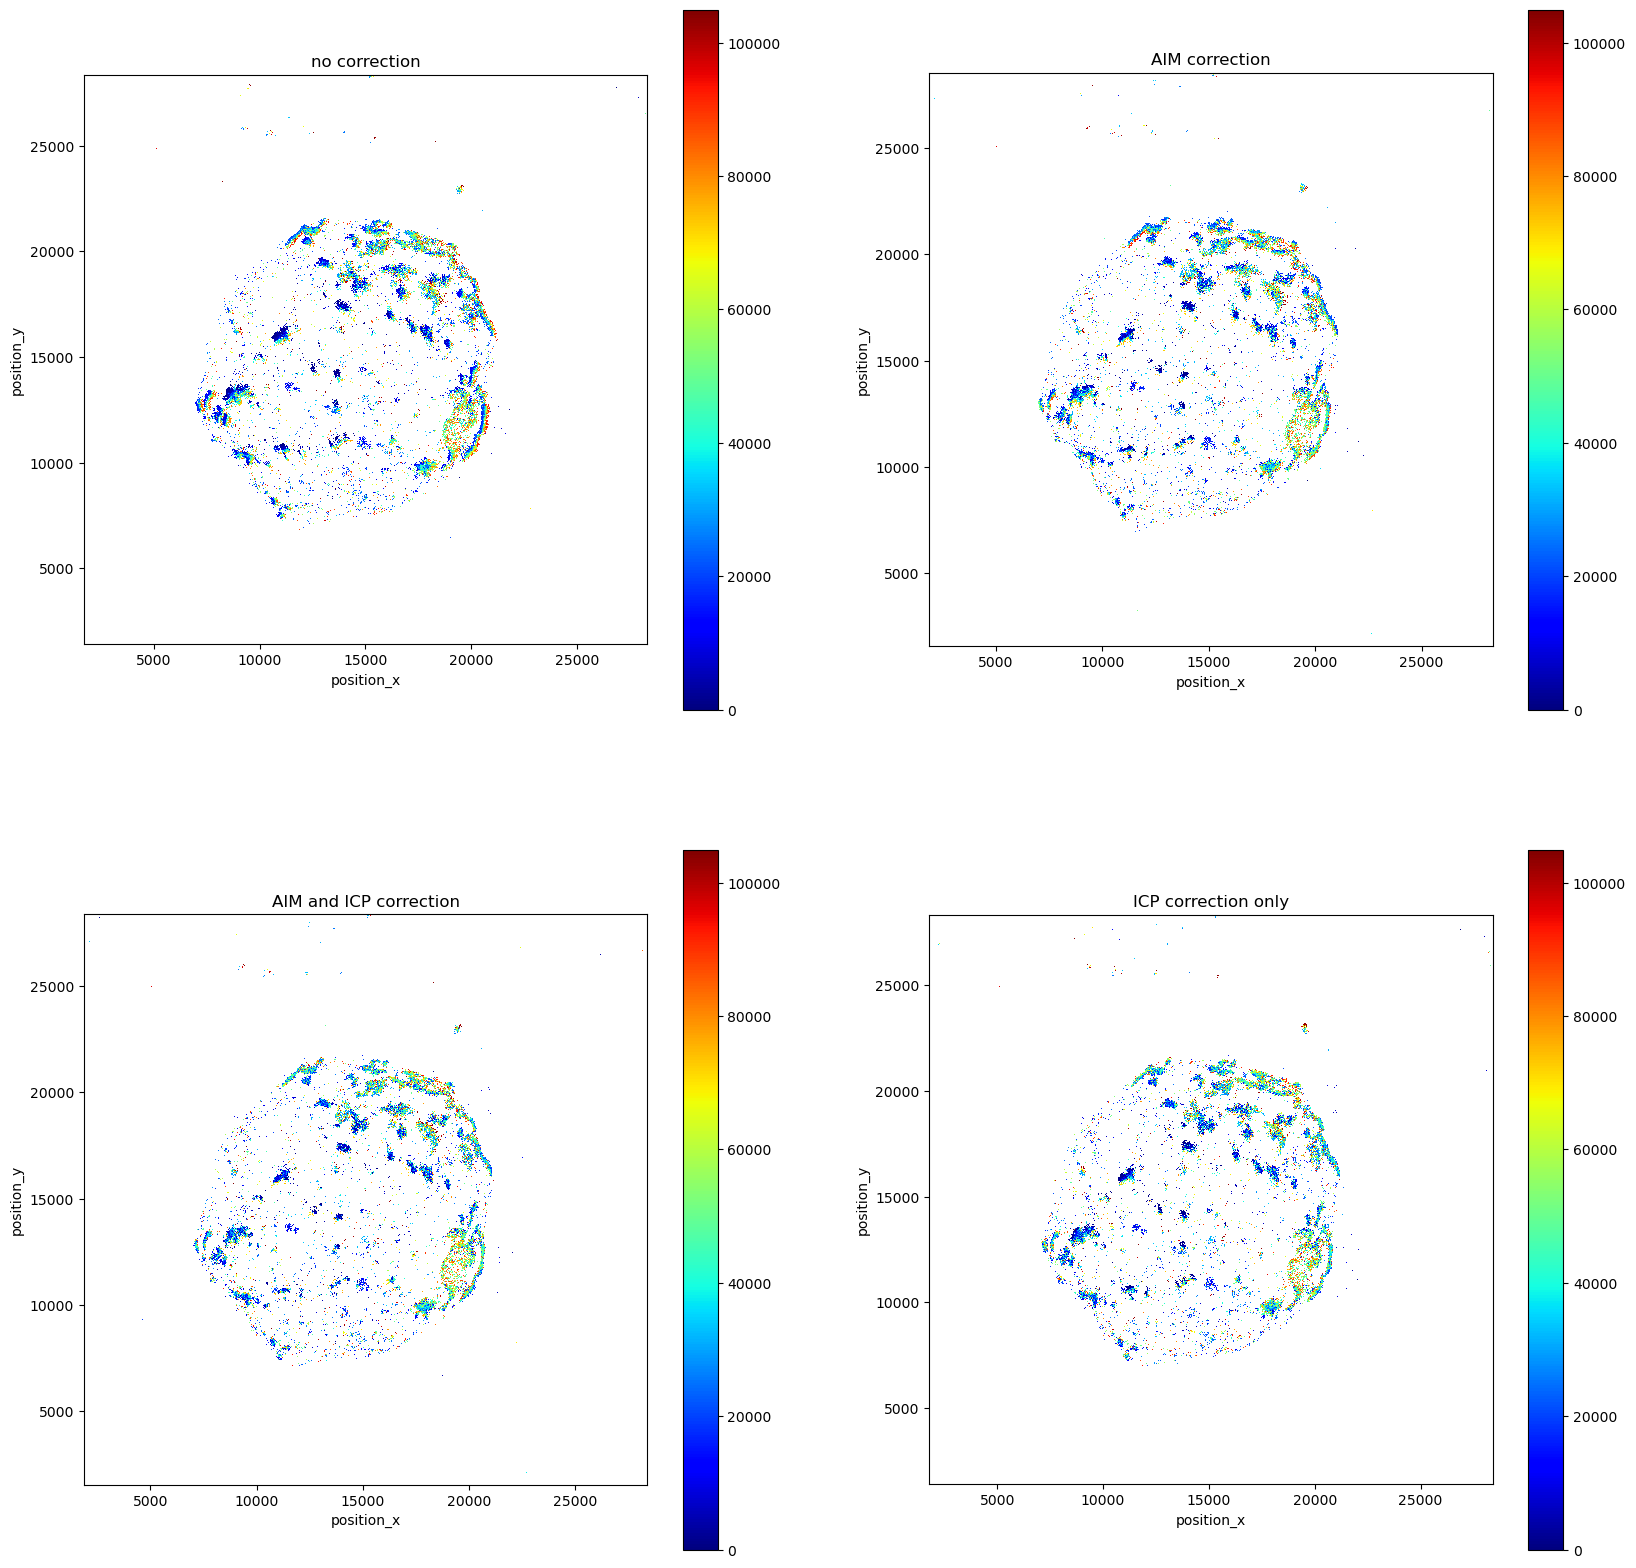

In [114]:
fig, axes = plt.subplots(2, 2, figsize=(20, 20))
plt.style.use('default')
lc.render_2d_mpl(dat_640_z_cor, loc_properties=['position_x', 'position_y'], ax= axes[0,0], bin_size=(20, 20),  other_property='frame', cmap='jet');
lc.render_2d_mpl(dat_640_xyz_cor, loc_properties=['position_x', 'position_y'], ax= axes[0,1], bin_size=(20, 20), other_property='frame', cmap = 'jet',);
lc.render_2d_mpl(icp_cor, loc_properties=['position_x', 'position_y'], ax= axes[1,0], bin_size=(20, 20), other_property='frame', cmap = 'jet',);
lc.render_2d_mpl(icp_cor_only, loc_properties=['position_x', 'position_y'], ax= axes[1,1], bin_size=(20, 20), other_property='frame', cmap = 'jet',);
axes[0,0].set_title("no correction")
axes[0,1].set_title("AIM correction")
axes[1,0].set_title("AIM and ICP correction")
axes[1,1].set_title("ICP correction only")

## 3.5 Select one drift correction option and apply

In [116]:
"""Define which correction should be applied (
 dat_640_z_cor : uncorrected
 dat_640_xyz_cor : AIM corrected
 icp_cor : AIM + ICP corrected
 icp_cor_only : ICP corrected only
 )
 """
dat_640_xyz_cor = deepcopy(icp_cor_only)

## 3.6 Correct offset mismatch in z 640 nm (in each z-stack)

In [117]:
step_size = 5_000
stack_rounds = 3
drift_chunks = []
z_offset = []
z_distances = []
comb_z_distances =[]
slices_p_round = int(len(shift_values_640)/stack_rounds) # calculate number of slices for a whole stack
for round in range(0, stack_rounds):
    print(f"round {round}")
    start_frame = 0 + (round*step_size) * slices_p_round
    middle_frame = start_frame + step_size
    stop_frame = start_frame + 2*step_size
    for slice in range(0, slices_p_round-1):
        print(f"slices {slice}")
        # first / target slice:
        first_slice = lc.select_by_condition(dat_640_xyz_cor, condition=f'{start_frame} <= frame < {middle_frame}')
        first_slice.reduce();
        first_slice = lc.select_by_condition(first_slice, condition=f'{shift_values_640[slice+(slices_p_round*round)+1]} < position_z < {shift_values_640[slice+(slices_p_round*round)]}')
        first_slice.reduce();

        # second / source slice:
        second_slice = lc.select_by_condition(dat_640_xyz_cor, condition=f'{middle_frame} <= frame < {stop_frame}')
        second_slice.reduce();
        second_slice = lc.select_by_condition(second_slice, condition=f'{shift_values_640[slice+(slices_p_round*round)+1]} < position_z < {shift_values_640[slice+(slices_p_round*round)]}')
        second_slice.reduce();

        # clustering of localisation in source and target frame
        noise, clust_sample = lc.cluster_dbscan(first_slice, eps=30, min_samples=3)
        noise, clust_target = lc.cluster_dbscan(second_slice, eps=30, min_samples=3)

        # find nearest neighbour
        coordinates = clust_target.coordinates[:,0:2]
        z_distance = []
        for pos in clust_sample.coordinates:
            distance, index = spatial.KDTree(coordinates).query(pos[0:2])
            z_distance.append(pos[2] - clust_target.coordinates[index, 2])
        z_offset.append(statistics.mean(z_distance))
        z_distances.append(z_distance)
        if round == 0:
            comb_z_distances.append(z_distance)
        else:
            comb_z_distances[slice].extend(z_distance)



        #print(first_slice.data.describe())
        #print(second_slice.data.describe())
        print(start_frame,middle_frame, stop_frame)



        start_frame +=step_size
        middle_frame +=step_size
        stop_frame += step_size

round 0
slices 0
0 5000 10000
slices 1
5000 10000 15000
slices 2
10000 15000 20000
slices 3
15000 20000 25000
slices 4
20000 25000 30000
slices 5
25000 30000 35000
round 1
slices 0
35000 40000 45000
slices 1
40000 45000 50000
slices 2
45000 50000 55000
slices 3
50000 55000 60000
slices 4
55000 60000 65000
slices 5
60000 65000 70000
round 2
slices 0
70000 75000 80000
slices 1
75000 80000 85000
slices 2
80000 85000 90000
slices 3
85000 90000 95000
slices 4
90000 95000 100000
slices 5
95000 100000 105000


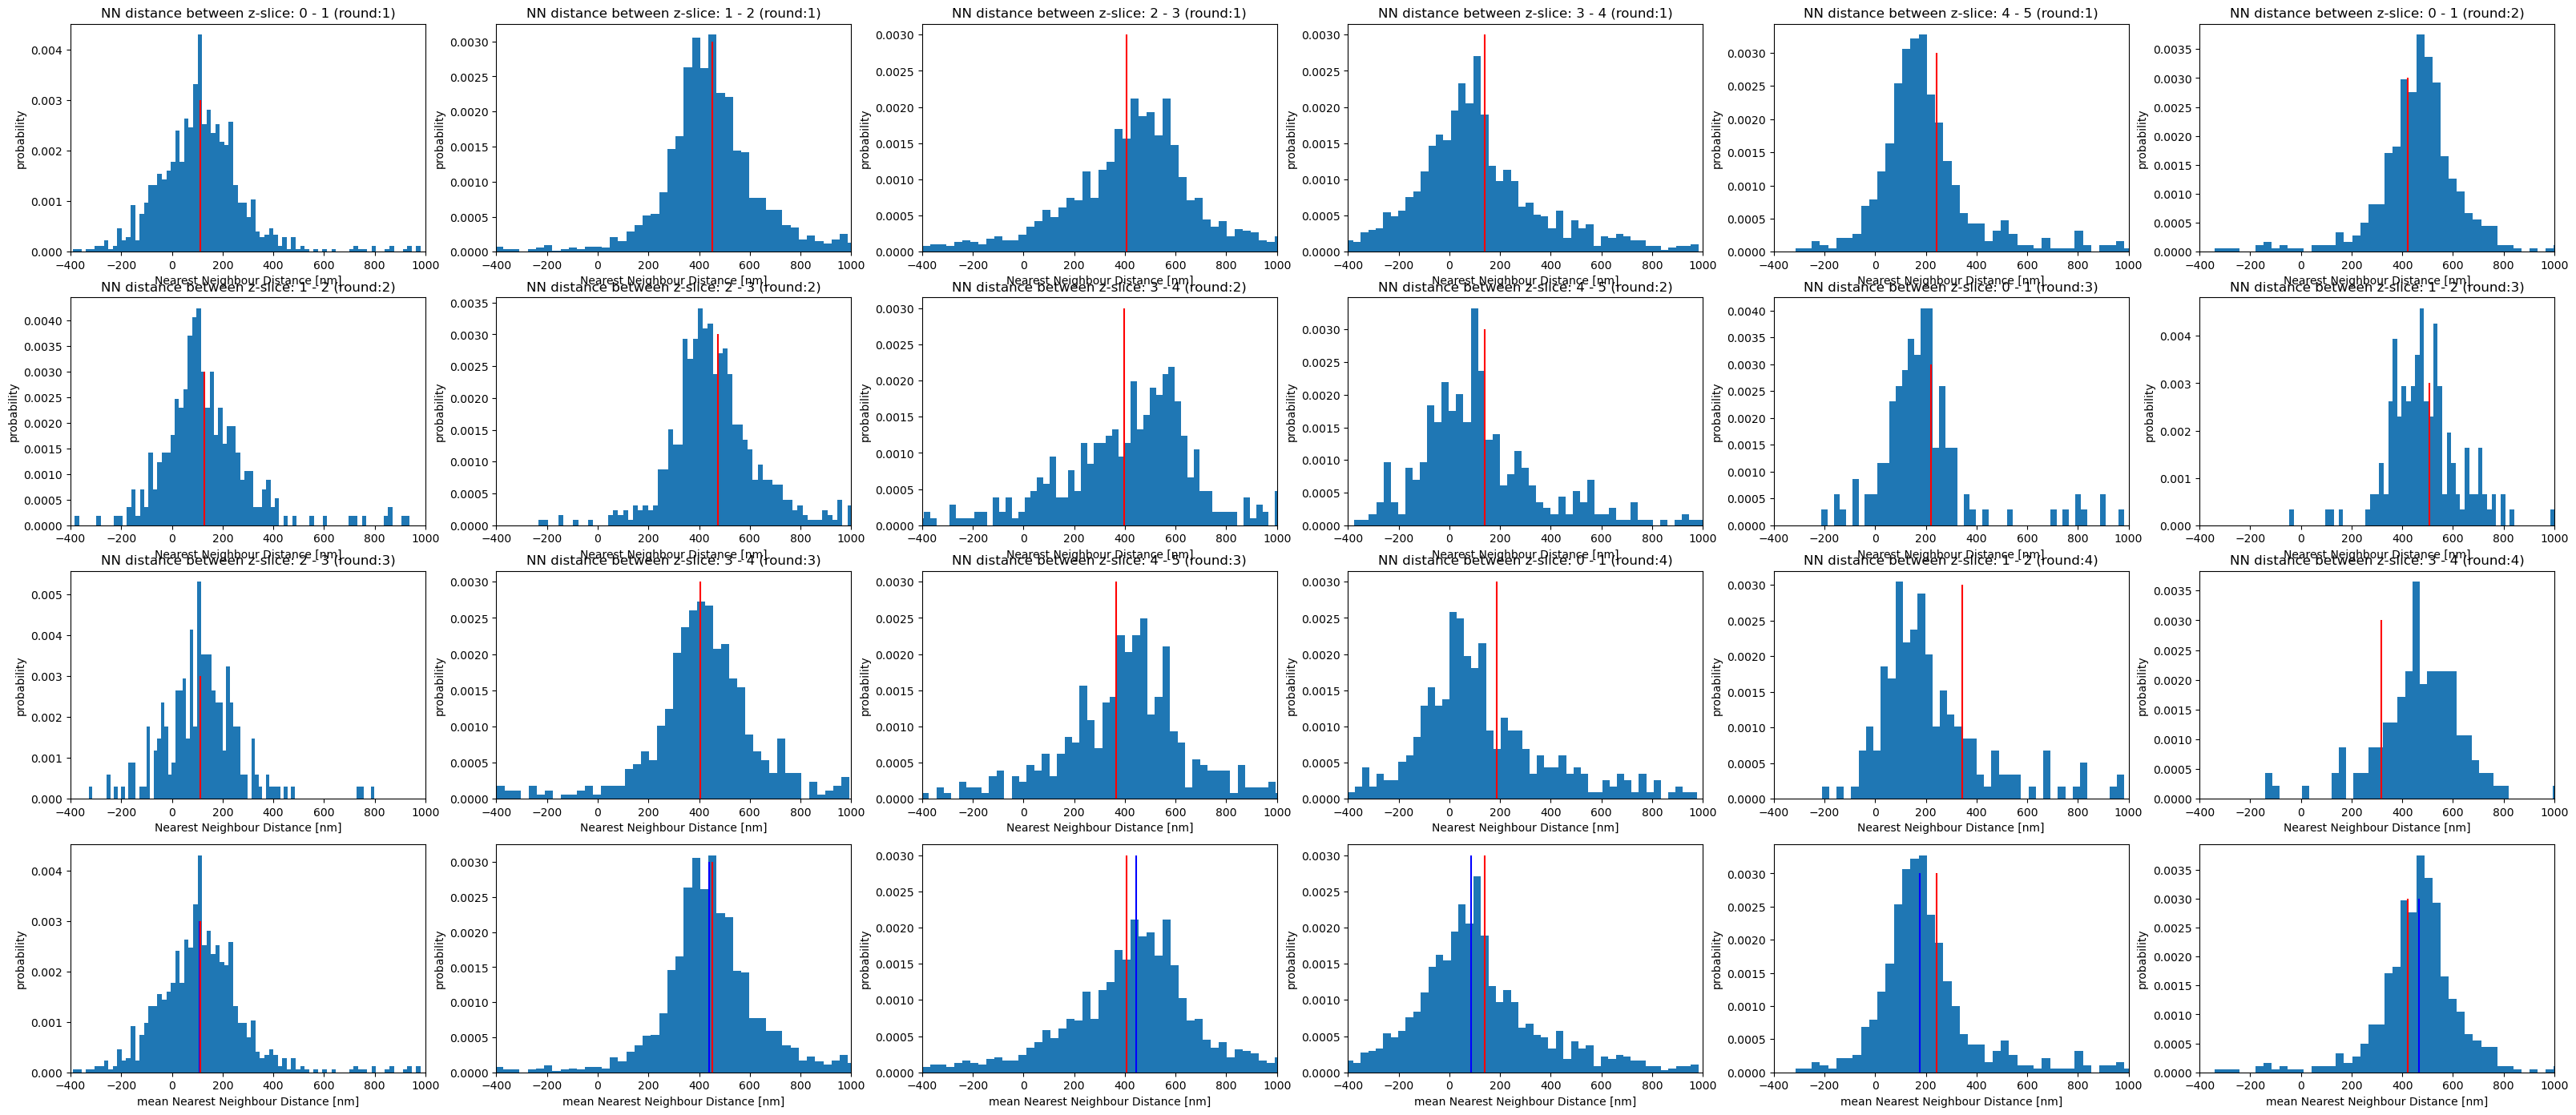

In [118]:
median_offset = []
mean_offset = []
for z_distance in comb_z_distances:
    median_offset.append(statistics.median(z_distance))
    mean_offset.append(statistics.mean(z_distance))
median_offset_640 = median_offset*3

fig, axes = plt.subplots(4, 6, figsize=(40, 17))
steps = 5
stack_rounds = 3
step = 1
round = 1
for z_distance, ax in zip(z_distances, axes.flatten()):
    ax.vlines(statistics.mean(z_distance), ymin= 0, ymax = 0.003,color='r', label='axvline - full height')
    ax.hist(z_distance, density=True, bins=100)
    ax.set_xlim(-400, 1000)
    ax.set_xlabel("Nearest Neighbour Distance [nm]")
    ax.set_ylabel("probability")

    ax.set_title(f"NN distance between z-slice: {step-1} - {step} (round:{round})")
    if step < steps:
        step += 1
    else:
        step = 1
        round += 1
count = 0
for z_distance in comb_z_distances:
    axes[3,count].vlines(median_offset[count], ymin= 0, ymax = 0.003,color='b', label='axvline - full height')
    axes[3,count].vlines(mean_offset[count], ymin= 0, ymax = 0.003,color='r', label='axvline - full height')
    axes[3,count].hist(z_distance, density=True, bins=100)
    axes[3,count].set_xlim(-400, 1000)
    axes[3,count].set_xlabel("mean Nearest Neighbour Distance [nm]")
    axes[3,count].set_ylabel("probability")
    #ax.plot(median_offset_640[0], 1)
    count += 1

    ax.set_title(f"NN distance between z-slice: {step-1} - {step} (round:{round})")


In [119]:
# calculate corrected Z-values
step_size = 5_000
stack_rounds = 3
cor_z_values = []
offset = 0
slices_p_round = int(len(shift_values_640)/stack_rounds) # calculate number of slices for a whole stack
for round in range(0, stack_rounds):
    print(f"round {round}")
    start_frame = 0 + (round*step_size) * slices_p_round
    stop_frame = start_frame + step_size
    previous_offset = 0
    for slice in range(0, slices_p_round):
        print(f"slices {slice}")
        if slice == 0:
            loc_slice = lc.select_by_condition(dat_640_xyz_cor, condition=f'{start_frame} <= frame < {stop_frame}')
            loc_slice.reduce();
            z_slice = loc_slice.data["position_z"]
            cor_z_values.extend(z_slice.to_list())
        else:
            loc_slice = lc.select_by_condition(dat_640_xyz_cor, condition=f'{start_frame} <= frame < {stop_frame}')
            loc_slice.reduce();
            z_slice = loc_slice.data["position_z"]
            z_slice += median_offset_640[offset]+previous_offset
            cor_z_values.extend(z_slice.to_list())
            print(offset)
            previous_offset += median_offset_640[offset]
            offset += 1
        print(stop_frame)
        start_frame += step_size
        stop_frame += step_size



round 0
slices 0
5000
slices 1
0
10000
slices 2
1
15000
slices 3
2
20000
slices 4
3
25000
slices 5
4
30000
slices 6
5
35000
round 1
slices 0
40000
slices 1
6
45000
slices 2
7
50000
slices 3
8
55000
slices 4
9
60000
slices 5
10
65000
slices 6
11
70000
round 2
slices 0
75000
slices 1
12
80000
slices 2
13
85000
slices 3
14
90000
slices 4
15
95000
slices 5
16
100000
slices 6
17
105000


In [120]:
# Apply correction
z_stack_offset_640 = median_offset_640
dat_640_xyz_of_cor = deepcopy(dat_640_xyz_cor)
dat_640_xyz_of_cor.data["position_z"] = cor_z_values

# 4. Drift and offset correction 532 nm
## 4.1 Correct lateral drift with AIM 532 nm

In [121]:
step_size = 5_000
stack_rounds = 3
drift_chunks = []
x_mean_drift = []
y_mean_drift = []
frames_mean_drift = []
slices_p_round = int(len(shift_values_532)/stack_rounds) # calculate number of slices for a whole stack
drift_cor_locs = deepcopy(dat_532_z_cor)
for round in range(0, stack_rounds):
    print(f"round {round}")
    start_frame = 0 + (round*step_size) * slices_p_round
    stop_frame = step_size*2 + (round*step_size) * slices_p_round
    for slice in range(0, slices_p_round-1):
        print(f"slices {slice}")
        locs_slice = lc.select_by_condition(drift_cor_locs, condition=f'{start_frame} <= frame < {stop_frame}')
        locs_slice.reduce();
        locs_slice = lc.select_by_condition(locs_slice, condition=f'{shift_values_532[slice+(slices_p_round*round)+1]} < position_z < {shift_values_532[slice+(slices_p_round*round)]}')
        locs_slice.reduce();
        locs_slice_cor, drift = rq.estimate_drift_aim(locs_slice, segmentation=800, n_frames = 2*step_size, intersect_d = 14/111, roi_r=20/111, roi_r_z= 20/111, first_frame=start_frame, thirdD= False)
        #print(locs_slice.data.describe())
        print(start_frame, stop_frame)

        print(round)
        print(slice)
        if round != 0 or slice != 0: # calculate offset between old frame and new frame to align drift chunks to each other
            x_mean_new = drift['x'][:step_size].mean()
            y_mean_new = drift['y'][:step_size].mean()
            x_offset = x_mean_new - x_mean_old
            y_offset = y_mean_new - y_mean_old
            print(x_offset)
            drift['x'] = drift['x'] - x_offset
            drift['y'] = drift['y'] - y_offset

        drift_chunks.append(drift)

        if slice == 0: # for the first slice append first half of drift chunk to the mean values
            x_mean_drift.extend(drift['x'][:step_size].tolist())
            y_mean_drift.extend(drift['y'][:step_size].tolist())
            frames_mean_drift.extend(drift['frame'][:step_size].tolist())
        elif slice == (slices_p_round-2): # for the last frame of one round calculate mean and append last half of drift chunk
            #append mean of first half of chunk:
            x_mean_drift.extend(((last_drift['x'] + drift['x'][:step_size])/2).tolist())
            y_mean_drift.extend(((last_drift['y'] + drift['y'][:step_size])/2).tolist())
            frames_mean_drift.extend(drift['frame'][:step_size].tolist())
            #append last half of chunk:
            x_mean_drift.extend(drift['x'][step_size:].tolist())
            y_mean_drift.extend(drift['y'][step_size:].tolist())
            frames_mean_drift.extend(drift['frame'][step_size:].tolist())
        else: # for all other frames calculate mean of first half and append
            x_mean_drift.extend(((last_drift['x'] + drift['x'][:step_size])/2).tolist())
            y_mean_drift.extend(((last_drift['y'] + drift['y'][:step_size])/2).tolist())
            frames_mean_drift.extend(drift['frame'][:step_size].tolist())

        last_drift = drift[step_size:]


        x_mean_old = drift['x'][5000:].mean()
        y_mean_old = drift['y'][5000:].mean()
        start_frame +=step_size
        stop_frame += step_size
mean_drift = np.rec.array((np.array(x_mean_drift), np.array(y_mean_drift), np.array(frames_mean_drift)),
                                  dtype=[("x", "f"), ("y", "f"), ("frame", "f")]
                                  )


round 0
slices 0


Undrifting (2/2): 100%|██████████| 13/13 [00:00<00:00, 273.38segment/s]


0 10000
0
0
slices 1


Undrifting (2/2): 100%|██████████| 13/13 [00:00<00:00, 252.09segment/s]


5000 15000
0
1
-2.872095
slices 2


...

85000 95000
2
3
-14.873515
slices 4


Undrifting (2/2): 100%|██████████| 13/13 [00:00<00:00, 240.38segment/s]


90000 100000
2
4
-43.77441
slices 5


Undrifting (2/2): 100%|██████████| 13/13 [00:00<00:00, 304.09segment/s]

95000 105000
2
5
-18.84261


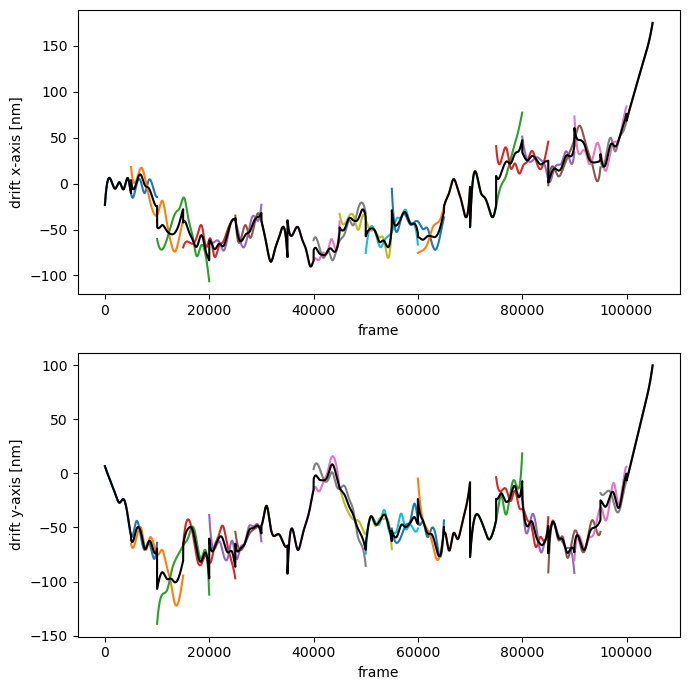

In [128]:
fig, axs = plt.subplots(nrows =2, ncols = 1, figsize = (7,7))
for chunk in drift_chunks:
    axs[0].plot(chunk['frame'], chunk['x'])
    axs[1].plot(chunk['frame'], chunk['y'])
axs[0].plot(mean_drift['frame'], mean_drift['x'], color = 'black')
axs[0].set_xlabel('frame')
axs[0].set_ylabel('drift x-axis [nm]')
axs[1].plot(mean_drift['frame'], mean_drift['y'], color = 'black')
axs[1].set_xlabel('frame')
axs[1].set_ylabel('drift y-axis [nm]')
fig.tight_layout()

In [124]:
drift_frames = mean_drift.tolist()
dat_532_xyz_cor = deepcopy(dat_532_z_cor)
coordinates = dat_532_xyz_cor.coordinates
frames = dat_532_xyz_cor.data.frame.values
f_coordinates = np.concatenate((coordinates, frames[:, None]), axis=1)
for coordinate in f_coordinates:
    drift = drift_frames[int(coordinate[3])]
    coordinate[0] = coordinate[0] - drift[0]
    coordinate[1] = coordinate[1] - drift[1]
dat_532_xyz_cor.data['position_x'] = f_coordinates[:,0]
dat_532_xyz_cor.data['position_y'] = f_coordinates[:,1]

In [129]:
# Correct x/y drift relative to the last frame; preserve z coordinates
dat_532_xyz_cor = deepcopy(dat_532_z_cor)

drift_frames = np.column_stack([
    mean_drift["x"],
    mean_drift["y"],
]).astype(float)

frames = dat_532_xyz_cor.data["frame"].to_numpy(dtype=int)

for axis, column in enumerate(["position_x", "position_y"]):
    coordinates = dat_532_z_cor.data[column].to_numpy(dtype=float)

    dat_532_xyz_cor.data[column] = (
        coordinates
        - drift_frames[frames, axis]
        + drift_frames[-1, axis]
    )

## 4.2 Correct drift with AIM and ICP combined

In [134]:
#lc.render_2d_mpl(dat_532_xyz_cor, loc_properties=['position_x', 'position_y'], ax=axes[1], bin_size=(20, 20),
                 #other_property='frame', cmap='jet', );
step_size = 5_000
stack_rounds = 3
slices_p_round = int(len(shift_values_640) / stack_rounds)  # calculate number of slices for a whole stack
first_slice = lc.select_by_condition(dat_532_xyz_cor, condition=f'{0} <= frame < {slices_p_round * step_size}')
first_slice.reduce();
second_slice = lc.select_by_condition(dat_532_xyz_cor,
                                      condition=f'{slices_p_round * step_size} <= frame < {slices_p_round * step_size * 2}')
second_slice.reduce();
third_slice = lc.select_by_condition(dat_532_xyz_cor,
                                     condition=f'{slices_p_round * step_size * 2} <= frame < {slices_p_round * step_size * 3}')
third_slice.reduce();

first_slice_cor, matrix = rq.align_locdata_ransac_icp(moving_ld=first_slice, fixed_ld=second_slice, align_z=False)
first_cor_second_uncor = lc.LocData.concat([first_slice_cor, second_slice])

first_second_cor, matrix = rq.align_locdata_ransac_icp(moving_ld=first_cor_second_uncor, fixed_ld=third_slice,
                                                       align_z=False)
icp_cor = lc.LocData.concat([first_second_cor, third_slice])

pc1 (moving) shape: (19129, 3)
pc2 (fixed) shape: (10293, 3)
align_z=False: using z=0 projection for registration.
Bounding box diagonal (target, registration coords): 39824.664
Centroid distance before registration (registration coords): 1017.5546

=== Global registration: RANSAC (Open3D) ===
RANSAC runtime: 0.092 s
RANSAC fitness: 0.9273354592503529 inlier RMSE: 356.8815456115188
RANSAC transformation:
 [[-7.26609034e-01 -6.87051171e-01  0.00000000e+00  3.69276541e+04]
 [ 6.87051171e-01 -7.26609034e-01  0.00000000e+00  1.62064081e+04]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]
RANSAC looks unreliable (low fitness, large translation, or high inlier RMSE).
Using identity as initial transform for ICP.

=== Multi-scale ICP refinement ===
ICP max correspondence distances (coarse → fine): [100.0, 60.0, 30.0]

--- ICP stage 1 with max_dist = 100.00 ---
ICP stage 1 runtime: 0.096 s
ICP stage 1 fitness

## 4.3 Correct drift with ICP

In [135]:
step_size = 5_000
stack_rounds = 3
slices_p_round = int(len(shift_values_640)/stack_rounds) # calculate number of slices for a whole stack
first_slice = lc.select_by_condition(dat_532_z_cor, condition=f'{0} <= frame < {slices_p_round*step_size}')
first_slice.reduce();
second_slice = lc.select_by_condition(dat_532_z_cor, condition=f'{slices_p_round*step_size} <= frame < {slices_p_round*step_size*2}')
second_slice.reduce();
third_slice = lc.select_by_condition(dat_532_z_cor, condition=f'{slices_p_round*step_size*2} <= frame < {slices_p_round*step_size*3}')
third_slice.reduce();

first_slice_cor, matrix = rq.align_locdata_ransac_icp(moving_ld = first_slice, fixed_ld = second_slice, align_z = False)
first_cor_second_uncor = lc.LocData.concat([first_slice_cor, second_slice])

first_second_cor, matrix = rq.align_locdata_ransac_icp(moving_ld = first_cor_second_uncor, fixed_ld = third_slice, align_z = False)
icp_cor_only = lc.LocData.concat([first_second_cor, third_slice])

pc1 (moving) shape: (19129, 3)
pc2 (fixed) shape: (10293, 3)
align_z=False: using z=0 projection for registration.
Bounding box diagonal (target, registration coords): 39775.922
Centroid distance before registration (registration coords): 1012.3097

=== Global registration: RANSAC (Open3D) ===
RANSAC runtime: 0.086 s
RANSAC fitness: 0.0 inlier RMSE: 0.0
RANSAC transformation:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
RANSAC looks unreliable (low fitness, large translation, or high inlier RMSE).
Using identity as initial transform for ICP.

=== Multi-scale ICP refinement ===
ICP max correspondence distances (coarse → fine): [100.0, 60.0, 30.0]

--- ICP stage 1 with max_dist = 100.00 ---
ICP stage 1 runtime: 0.096 s
ICP stage 1 fitness: 0.5988, inlier RMSE: 45.5566

--- ICP stage 2 with max_dist = 60.00 ---
ICP stage 2 runtime: 0.098 s
ICP stage 2 fitness: 0.4732, inlier RMSE: 30.4207

--- ICP stage 3 with max_dist = 30.00 ---
ICP stage 3 runtime: 0.093 s
ICP stage 3 

## 4.4 Display drift corrected images

Text(0.5, 1.0, 'ICP correction only')

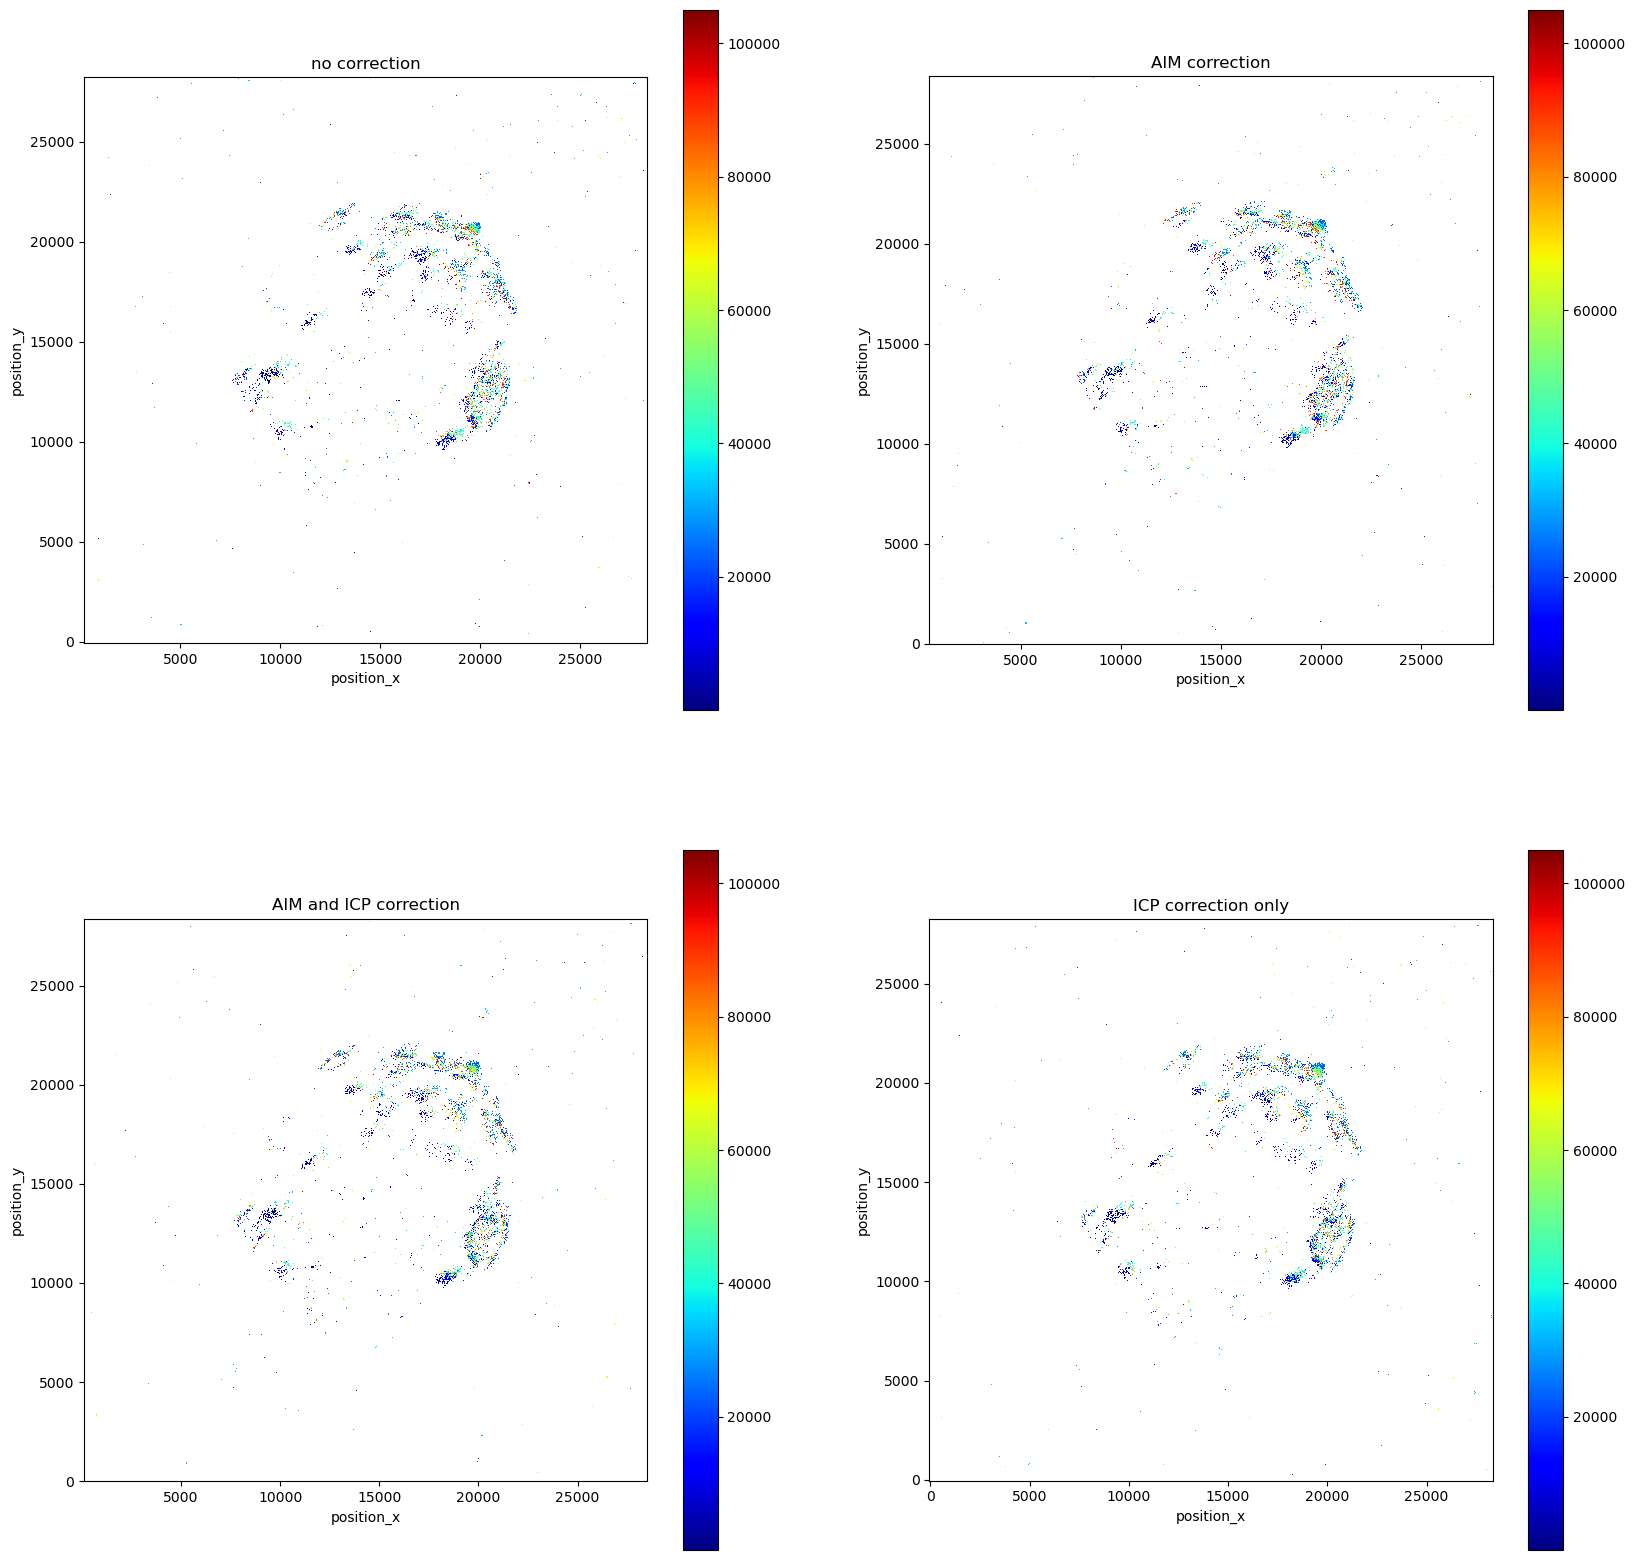

In [136]:
fig, axes = plt.subplots(2, 2, figsize=(20, 20))
plt.style.use('default')
lc.render_2d_mpl(dat_532_z_cor, loc_properties=['position_x', 'position_y'], ax= axes[0,0], bin_size=(20, 20),  other_property='frame', cmap='jet');
lc.render_2d_mpl(dat_532_xyz_cor, loc_properties=['position_x', 'position_y'], ax= axes[0,1], bin_size=(20, 20), other_property='frame', cmap = 'jet',);
lc.render_2d_mpl(icp_cor, loc_properties=['position_x', 'position_y'], ax= axes[1,0], bin_size=(20, 20), other_property='frame', cmap = 'jet',);
lc.render_2d_mpl(icp_cor_only, loc_properties=['position_x', 'position_y'], ax= axes[1,1], bin_size=(20, 20), other_property='frame', cmap = 'jet',);
axes[0,0].set_title("no correction")
axes[0,1].set_title("AIM correction")
axes[1,0].set_title("AIM and ICP correction")
axes[1,1].set_title("ICP correction only")

## 4.5 Select one drift correction option and apply

In [137]:
"""Define which correction should be applied (
 dat_640_z_cor : uncorrected
 dat_640_xyz_cor : AIM corrected
 icp_cor : AIM + ICP corrected
 icp_cor_only : ICP corrected only
 )
 """
dat_532_xyz_cor = deepcopy(icp_cor_only)

## 4.6 Correct offset mismatch in z 532 nm (in each z-stack)

In [138]:
step_size = 5_000
stack_rounds = 3
drift_chunks = []
z_distances = []
comb_z_distances =[]
slices_p_round = int(len(shift_values_532)/stack_rounds) # calculate number of slices for a whole stack
for round in range(0, stack_rounds):
    print(f"round {round}")
    start_frame = 0 + (round*step_size) * slices_p_round
    middle_frame = start_frame + step_size
    stop_frame = start_frame + 2*step_size
    for slice in range(0, slices_p_round-1):
        print(f"slices {slice}")
        # first / target slice:
        first_slice = lc.select_by_condition(dat_532_xyz_cor, condition=f'{start_frame} <= frame < {middle_frame}')
        first_slice.reduce();
        first_slice = lc.select_by_condition(first_slice, condition=f'{shift_values_532[slice+(slices_p_round*round)+1]} < position_z < {shift_values_532[slice+(slices_p_round*round)]}')
        first_slice.reduce();

        # second / source slice:
        second_slice = lc.select_by_condition(dat_532_xyz_cor, condition=f'{middle_frame} <= frame < {stop_frame}')
        second_slice.reduce();
        second_slice = lc.select_by_condition(second_slice, condition=f'{shift_values_532[slice+(slices_p_round*round)+1]} < position_z < {shift_values_532[slice+(slices_p_round*round)]}')
        second_slice.reduce();

        # clustering of localisation in source and target frame
        noise, clust_sample = lc.cluster_dbscan(first_slice, eps=30, min_samples=3)
        noise, clust_target = lc.cluster_dbscan(second_slice, eps=30, min_samples=3)

        # find nearest neighbour
        coordinates = clust_target.coordinates[:,0:2]
        z_distance = []
        for pos in clust_sample.coordinates:
            distance, index = spatial.KDTree(coordinates).query(pos[0:2])
            z_distance.append(pos[2] - clust_target.coordinates[index, 2])
        z_distances.append(z_distance)
        if round == 0:
            comb_z_distances.append(z_distance)
        else:
            comb_z_distances[slice].extend(z_distance)



        #print(first_slice.data.describe())
        #print(second_slice.data.describe())
        print(start_frame,middle_frame, stop_frame)



        start_frame +=step_size
        middle_frame +=step_size
        stop_frame += step_size

round 0
slices 0
0 5000 10000
slices 1
5000 10000 15000
slices 2
10000 15000 20000
slices 3
15000 20000 25000
slices 4
20000 25000 30000
slices 5
25000 30000 35000
round 1
slices 0
35000 40000 45000
slices 1
40000 45000 50000
slices 2
45000 50000 55000
slices 3
50000 55000 60000
slices 4
55000 60000 65000
slices 5
60000 65000 70000
round 2
slices 0
70000 75000 80000
slices 1
75000 80000 85000
slices 2
80000 85000 90000
slices 3
85000 90000 95000
slices 4
90000 95000 100000
slices 5
95000 100000 105000


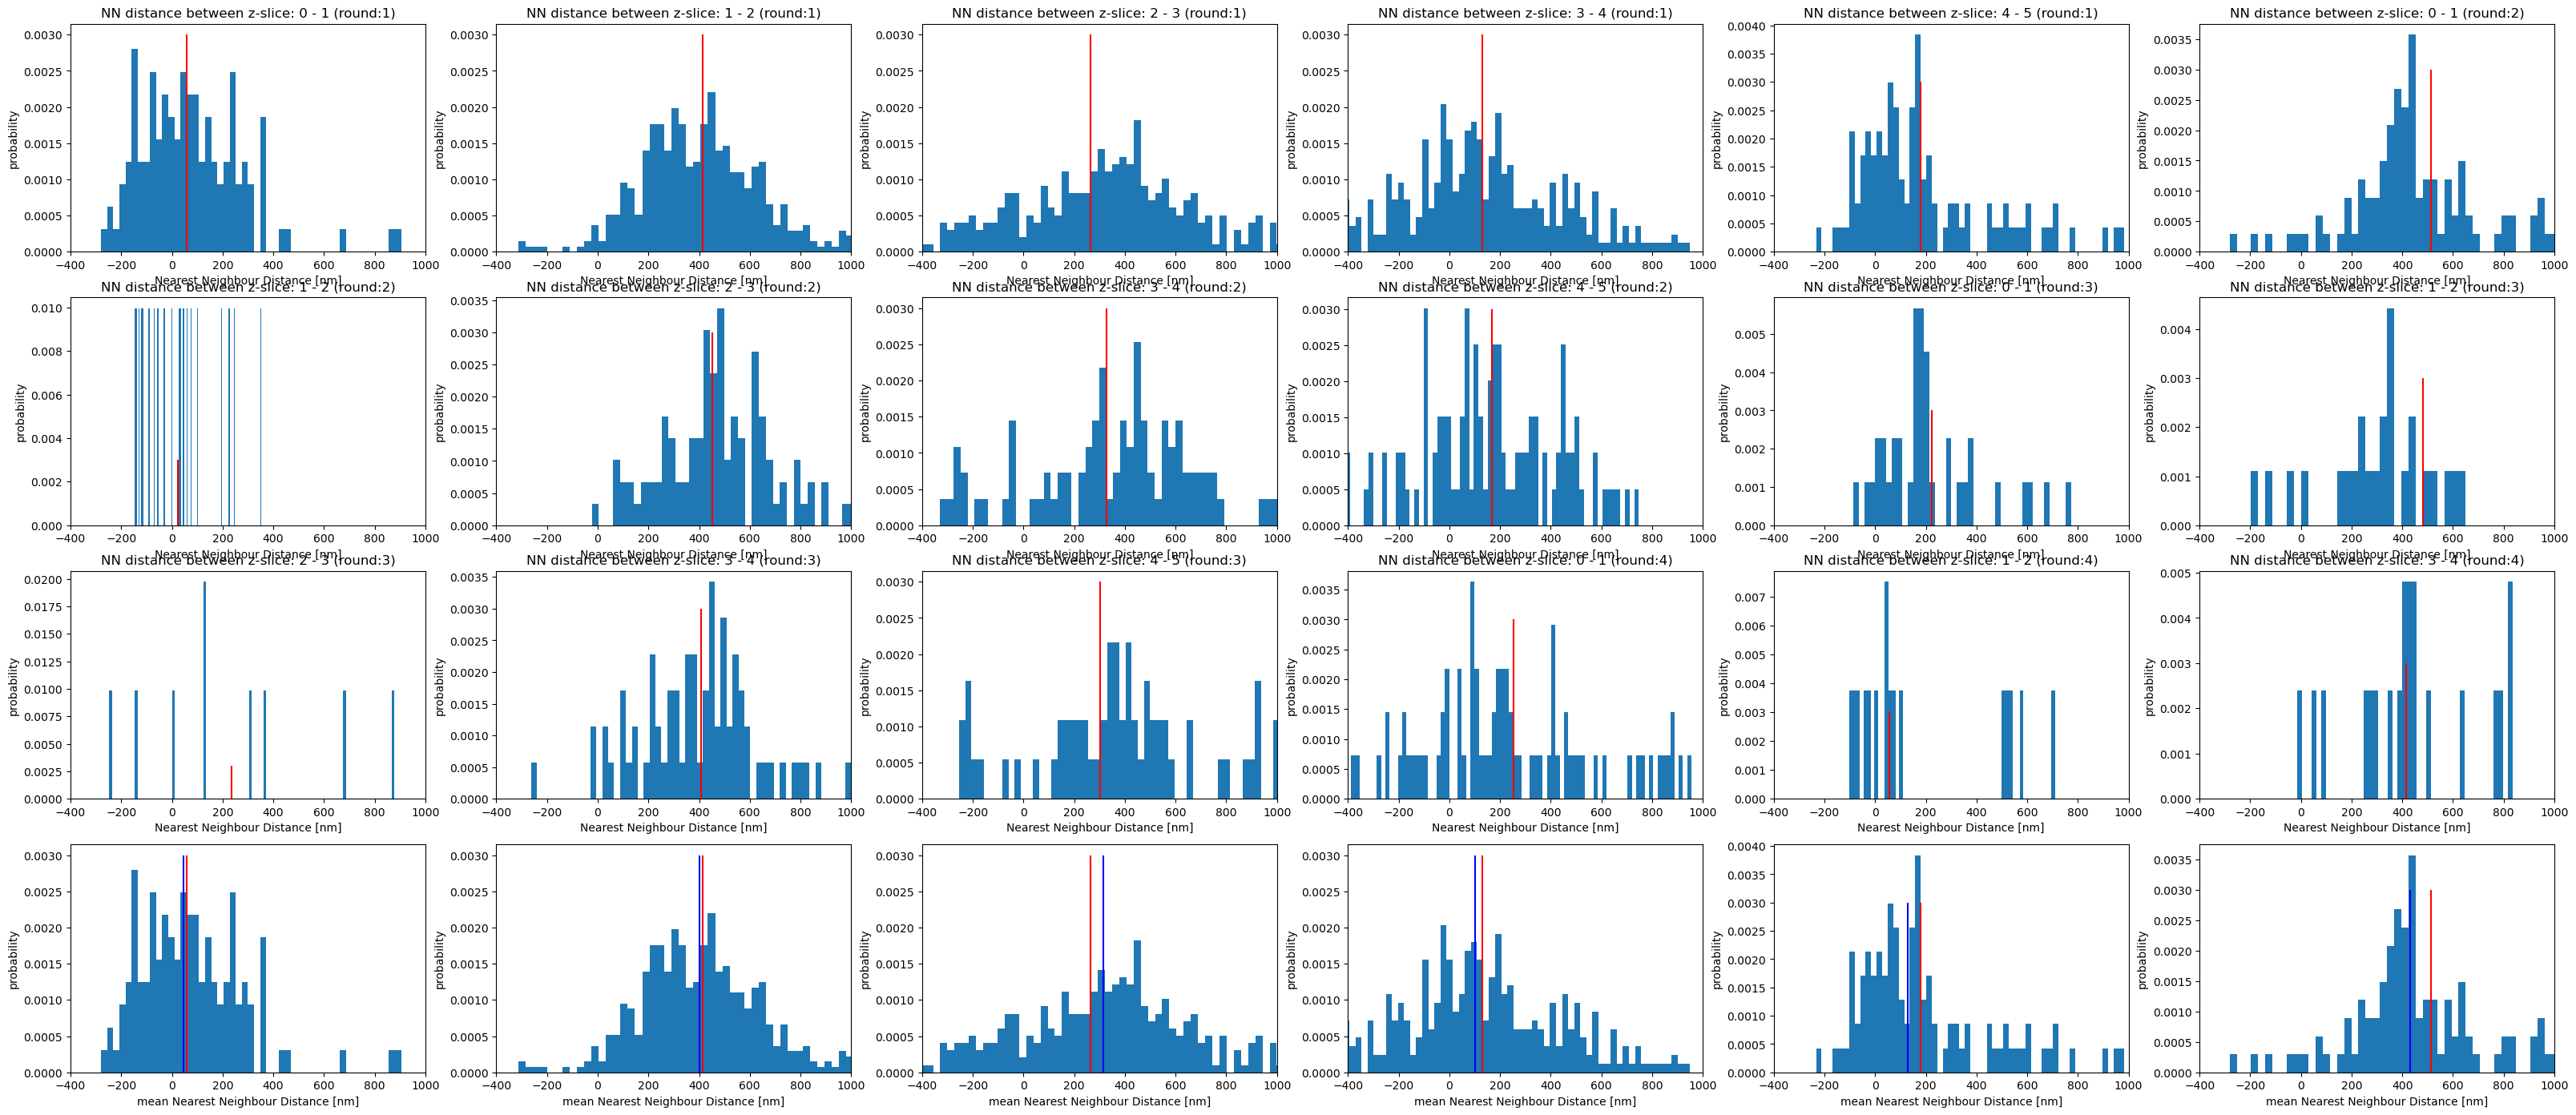

In [139]:
median_offset = []
mean_offset = []
for z_distance in comb_z_distances:
    median_offset.append(statistics.median(z_distance))
    mean_offset.append(statistics.mean(z_distance))
median_offset_532 = median_offset*3

fig, axes = plt.subplots(4, 6, figsize=(40, 17))
steps = 5
stack_rounds = 3
step = 1
round = 1
for z_distance, ax in zip(z_distances, axes.flatten()):
    ax.vlines(statistics.mean(z_distance), ymin= 0, ymax = 0.003,color='r', label='axvline - full height')
    ax.hist(z_distance, density=True, bins=100)
    ax.set_xlim(-400, 1000)
    ax.set_xlabel("Nearest Neighbour Distance [nm]")
    ax.set_ylabel("probability")

    ax.set_title(f"NN distance between z-slice: {step-1} - {step} (round:{round})")
    if step < steps:
        step += 1
    else:
        step = 1
        round += 1
count = 0
for z_distance in comb_z_distances:
    axes[3,count].vlines(median_offset[count], ymin= 0, ymax = 0.003,color='b', label='axvline - full height')
    axes[3,count].vlines(mean_offset[count], ymin= 0, ymax = 0.003,color='r', label='axvline - full height')
    axes[3,count].hist(z_distance, density=True, bins=100)
    axes[3,count].set_xlim(-400, 1000)
    axes[3,count].set_xlabel("mean Nearest Neighbour Distance [nm]")
    axes[3,count].set_ylabel("probability")
    #ax.plot(median_offset_640[0], 1)
    count += 1

    ax.set_title(f"NN distance between z-slice: {step-1} - {step} (round:{round})")

In [140]:
# use z-offset values from 640 nm channel, if localizations in 532nm channel are to sparse:
z_offset = z_stack_offset_640

In [141]:
# calculate corrected Z-values
step_size = 5_000
stack_rounds = 3
cor_z_values = []
offset = 0
slices_p_round = int(len(shift_values_532)/stack_rounds) # calculate number of slices for a whole stack
for round in range(0, stack_rounds):
    print(f"round {round}")
    start_frame = 0 + (round*step_size) * slices_p_round
    stop_frame = start_frame + step_size
    previous_offset = 0
    for slice in range(0, slices_p_round):
        print(f"slices {slice}")
        if slice == 0:
            loc_slice = lc.select_by_condition(dat_532_xyz_cor, condition=f'{start_frame} <= frame < {stop_frame}')
            loc_slice.reduce();
            z_slice = loc_slice.data["position_z"]
            cor_z_values.extend(z_slice.to_list())
        else:
            loc_slice = lc.select_by_condition(dat_532_xyz_cor, condition=f'{start_frame} <= frame < {stop_frame}')
            loc_slice.reduce();
            z_slice = loc_slice.data["position_z"]
            z_slice += z_offset[offset]+previous_offset
            print(len(z_slice))
            cor_z_values.extend(z_slice.to_list())
            print(offset)
            previous_offset += z_offset[offset]
            offset += 1
        print(stop_frame)
        start_frame += step_size
        stop_frame += step_size


round 0
slices 0
5000
slices 1
4303
0
10000
slices 2
4173
1
15000
slices 3
3684
2
20000
slices 4
2698
3
25000
slices 5
1500
4
30000
slices 6
1159
5
35000
round 1
slices 0
40000
slices 1
1814
6
45000
slices 2
2371
7
50000
slices 3
2641
8
55000
slices 4
1645
9
60000
slices 5
795
10
65000
slices 6
673
11
70000
round 2
slices 0
75000
slices 1
1110
12
80000
slices 2
1658
13
85000
slices 3
1816
14
90000
slices 4
1082
15
95000
slices 5
540
16
100000
slices 6
495
17
105000


In [142]:
# apply correction
dat_532_xyz_of_cor = deepcopy(dat_532_xyz_cor)
dat_532_xyz_of_cor.data["position_z"] = cor_z_values

# 5. Align different channels to each other with RANSAC and ICP

In [143]:
dat_532_xyz_of_cor_al, T_icp = rq.align_locdata_ransac_icp(moving_ld = dat_532_xyz_of_cor, fixed_ld = dat_640_xyz_of_cor, align_z = True)

pc1 (moving) shape: (36350, 3)
pc2 (fixed) shape: (186562, 3)
Bounding box diagonal (target, registration coords): 39862.340
Centroid distance before registration (registration coords): 2144.9062

=== Global registration: RANSAC (Open3D) ===
RANSAC runtime: 129.033 s
RANSAC fitness: 0.9568638239339753 inlier RMSE: 197.17776394614688
RANSAC transformation:
 [[ 9.97522802e-01  6.93523695e-02  1.17689408e-02 -1.71992026e+03]
 [-6.87791458e-02  9.96678309e-01 -4.36093763e-02  1.12438446e+03]
 [-1.47542616e-02  4.26918895e-02  9.98979336e-01 -5.23004452e+02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]
RANSAC looks unreliable (low fitness, large translation, or high inlier RMSE).
Using identity as initial transform for ICP.

=== Multi-scale ICP refinement ===
ICP max correspondence distances (coarse → fine): [100.0, 60.0, 30.0]

--- ICP stage 1 with max_dist = 100.00 ---
ICP stage 1 runtime: 0.397 s
ICP stage 1 fitness: 0.7756, inlier RMSE: 46.2605

--- ICP stage 2 wi

# 6. Quality control

C:\Users\ris82dr\AppData\Local\Temp\ipykernel_44332\2814268812.py:30: RuntimeWarning: invalid value encountered in divide
  mean_values = sum/count[:,0]


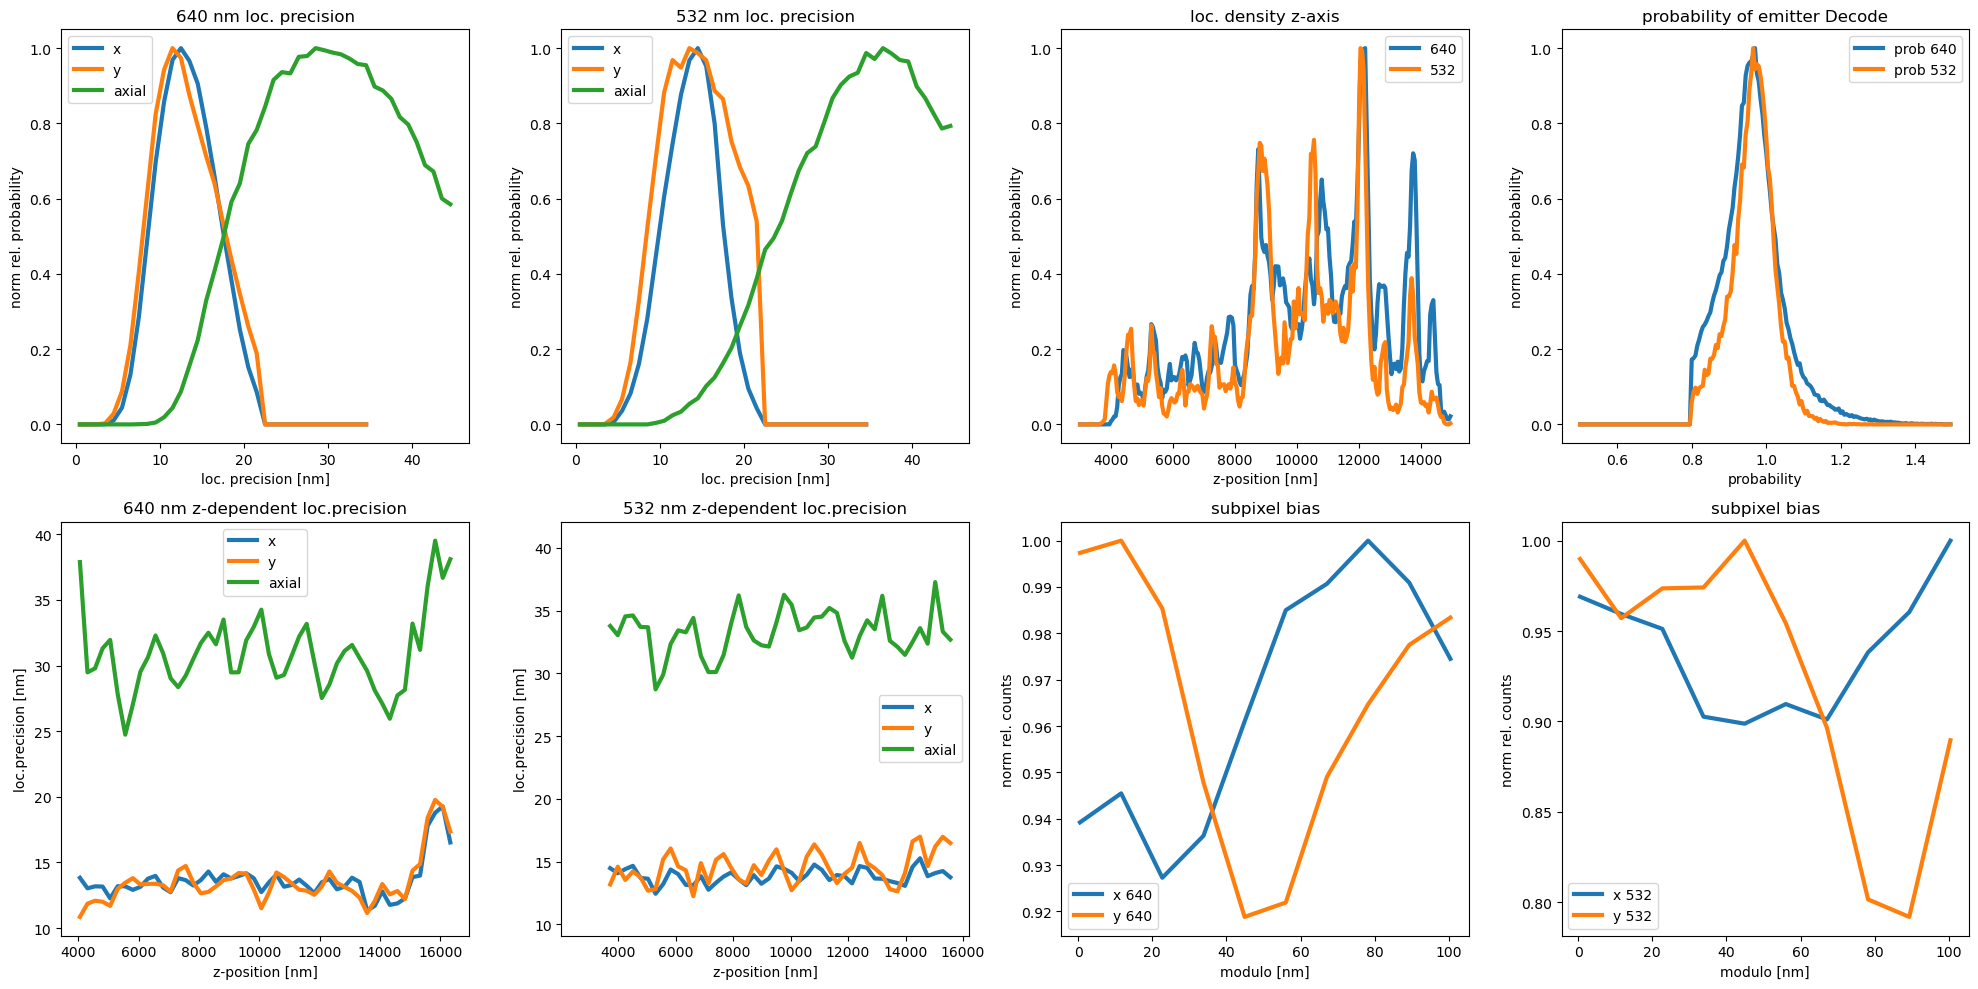

In [144]:
dat_532 = dat_532_xyz_of_cor_al
dat_640 = dat_640_xyz_of_cor

#plt.style.use('dark_background')

def calc_bins(bin, min_bin, max_bin, data):
    bins = np.arange(min_bin, max_bin + bin, bin)
    hist, bin_edges = np.histogram(data, bins)
    bin_edges = bin_edges[:-1] + 0.5
    return hist, bin_edges

def calc_bins_norm_zero(bin, min_bin, max_bin, data):
    bins = np.arange(min_bin, max_bin + bin, bin)
    hist, bin_edges = np.histogram(data, bins)
    hist = (hist - np.min(hist))/np.ptp(hist) # normalize Data between 0 and 1
    bin_edges = bin_edges[:-1] + 0.5
    return hist, bin_edges

def calc_bins_norm(bin, min_bin, max_bin, data):
    bins = np.arange(min_bin, max_bin + bin, bin)
    hist, bin_edges = np.histogram(data, bins)
    hist = hist/np.max(hist) # normalize Data between 0 and 1
    bin_edges = bin_edges[:-1] + 0.5
    return hist, bin_edges


def mean_loc_prec(z_pos, locprecnm, bin):
    count = np.histogram2d(z_pos, locprecnm, bins=[bin, 1])[0]
    sum = np.histogram(z_pos, weights=locprecnm, bins=bin)[0]
    mean_values = sum/count[:,0]
    z_edges = np.histogram(z_pos, weights=locprecnm, bins=bin)[1]
    z_centers = np.mean(np.vstack([z_edges[:-1], z_edges[1:]]), axis=0)
    return mean_values, z_centers




# lateral
lat_bin = 1
lat_min_bin = 0
lat_max_bin = 35

# axial
ax_bin = 1
ax_min_bin = 0
ax_max_bin = 45

# Z
z_bin = 50
z_min_bin = 3_000
z_max_bin = 15_000

# mod
mod_bin = 11.1
mod_min_bin = 0
mod_max_bin = 111

# prob
prob_bin = 0.005
prob_min_bin = 0
prob_max_bin = 1

fig, axs = plt.subplots(nrows = 2, ncols = 4, figsize = (20,10))


x_hist, lat_bin_edges = calc_bins_norm(lat_bin, lat_min_bin, lat_max_bin, dat_640.data.x_sig)
axs[0,0].plot(lat_bin_edges, x_hist, label = "x", linewidth=3)

y_hist, lat_bin_edges = calc_bins_norm(lat_bin, lat_min_bin, lat_max_bin, dat_640.data.y_sig)
axs[0,0].plot(lat_bin_edges, y_hist, label = "y", linewidth=3)

ax_hist, ax_bin_edges = calc_bins_norm(ax_bin, ax_min_bin, ax_max_bin, dat_640.data.z_sig)
axs[0,0].plot(ax_bin_edges, ax_hist, label = "axial", linewidth=3)
axs[0,0].legend()
axs[0,0].set_title("640 nm loc. precision")
axs[0,0].set_xlabel("loc. precision [nm]")
axs[0,0].set_ylabel("norm rel. probability")


x_hist, lat_bin_edges = calc_bins_norm(lat_bin, lat_min_bin, lat_max_bin, dat_532.data.x_sig)
axs[0,1].plot(lat_bin_edges, x_hist, label = "x", linewidth=3)

y_hist, lat_bin_edges = calc_bins_norm(lat_bin, lat_min_bin, lat_max_bin, dat_532.data.y_sig)
axs[0,1].plot(lat_bin_edges, y_hist, label = "y", linewidth=3)

ax_hist, ax_bin_edges = calc_bins_norm(ax_bin, ax_min_bin, ax_max_bin, dat_532.data.z_sig)
axs[0,1].plot(ax_bin_edges, ax_hist, label = "axial", linewidth=3)
axs[0,1].legend()
axs[0,1].set_title("532 nm loc. precision")
axs[0,1].set_xlabel("loc. precision [nm]")
axs[0,1].set_ylabel("norm rel. probability")

z_hist, z_bin_edges = calc_bins_norm(z_bin, z_min_bin, z_max_bin, dat_640.data.position_z)
axs[0,2].plot(z_bin_edges, z_hist, label = "640", linewidth=3)

z_hist, z_bin_edges = calc_bins_norm(z_bin, z_min_bin, z_max_bin, dat_532.data.position_z)
axs[0,2].plot(z_bin_edges, z_hist, label = "532", linewidth=3)
axs[0,2].legend()
axs[0,2].set_title("loc. density z-axis")
axs[0,2].set_xlabel("z-position [nm]")
axs[0,2].set_ylabel("norm rel. probability")
#axs[0,2].set_xlim(50,350)


modulo = lc.analysis.subpixel_bias._subpixel_bias(dat_640, pixel_size=pixelsize)

mod_hist, mod_bin_edges = calc_bins_norm(mod_bin, mod_min_bin, mod_max_bin, modulo.position_x_modulo)
axs[1,2].plot(mod_bin_edges, mod_hist, label = "x 640", linewidth=3)

mod_hist, mod_bin_edges = calc_bins_norm(mod_bin, mod_min_bin, mod_max_bin, modulo.position_y_modulo)
axs[1,2].plot(mod_bin_edges, mod_hist, label = "y 640", linewidth=3)
axs[1,2].legend()
axs[1,2].set_title("subpixel bias")
axs[1,2].set_xlabel("modulo [nm]")
axs[1,2].set_ylabel("norm rel. counts")


modulo = lc.analysis.subpixel_bias._subpixel_bias(dat_532, pixel_size=111)

mod_hist, mod_bin_edges = calc_bins_norm(mod_bin, mod_min_bin, mod_max_bin, modulo.position_x_modulo)
axs[1,3].plot(mod_bin_edges, mod_hist, label = "x 532", linewidth=3)

mod_hist, mod_bin_edges = calc_bins_norm(mod_bin, mod_min_bin, mod_max_bin, modulo.position_y_modulo)
axs[1,3].plot(mod_bin_edges, mod_hist, label = "y 532", linewidth=3)
axs[1,3].legend()
axs[1,3].set_title("subpixel bias")
axs[1,3].set_xlabel("modulo [nm]")
axs[1,3].set_ylabel("norm rel. counts")


locprec_x, z_values_x = mean_loc_prec(dat_640.data.position_z, dat_640.data.x_sig, bin = 50)
locprec_y, z_values_y = mean_loc_prec(dat_640.data.position_z, dat_640.data.y_sig, bin = 50)
locprec_ax, z_values_ax = mean_loc_prec(dat_640.data.position_z, dat_640.data.z_sig, bin = 50)
axs[1,0].plot(z_values_x, locprec_x, label = "x", linewidth=3)
axs[1,0].plot(z_values_y, locprec_y, label = "y", linewidth=3)
axs[1,0].plot(z_values_ax, locprec_ax, label = "axial", linewidth=3)
#axs[1,0].scatter(dat_640.data.position_z, dat_640.data.locprecnm, color="lightblue")
#axs[1,0].scatter(dat_640.data.position_z, dat_640.data.locprecznm, color="bisque")
axs[1,0].legend()
axs[1,0].set_title("640 nm z-dependent loc.precision")
axs[1,0].set_ylabel("loc.precision [nm]")
axs[1,0].set_xlabel("z-position [nm]")


locprec_x, z_values_x = mean_loc_prec(dat_532.data.position_z, dat_532.data.x_sig, bin = 50)
locprec_y, z_values_y = mean_loc_prec(dat_532.data.position_z, dat_532.data.y_sig, bin = 50)
locprec_ax, z_values_ax = mean_loc_prec(dat_532.data.position_z, dat_532.data.z_sig, bin = 50)
axs[1,1].plot(z_values_x, locprec_x, label = "x", linewidth=3)
axs[1,1].plot(z_values_y, locprec_y, label = "y", linewidth=3)
axs[1,1].plot(z_values_ax, locprec_ax, label = "axial", linewidth=3)
axs[1,1].legend()
axs[1,1].set_title("532 nm z-dependent loc.precision")
axs[1,1].set_ylabel("loc.precision [nm]")
axs[1,1].set_xlabel("z-position [nm]")
fig.tight_layout()

prob_640_hist, prob_640_bin_edges = calc_bins_norm(prob_bin, prob_min_bin, prob_max_bin, dat_640.data.prob)
axs[0,3].plot(prob_640_bin_edges, prob_640_hist, label = "prob 640", linewidth=3)

prob_532_hist, prob_532_bin_edges = calc_bins_norm(prob_bin, prob_min_bin, prob_max_bin, dat_532.data.prob)
axs[0,3].plot(prob_532_bin_edges, prob_532_hist, label = "prob 532", linewidth=3)
axs[0,3].legend()
axs[0,3].set_title("probability of emitter Decode")
axs[0,3].set_xlabel("probability")
axs[0,3].set_ylabel("norm rel. probability")
filename = os.path.splitext(loc_file_640)[0]+"_precision_plot.png"
fig.savefig(filename)

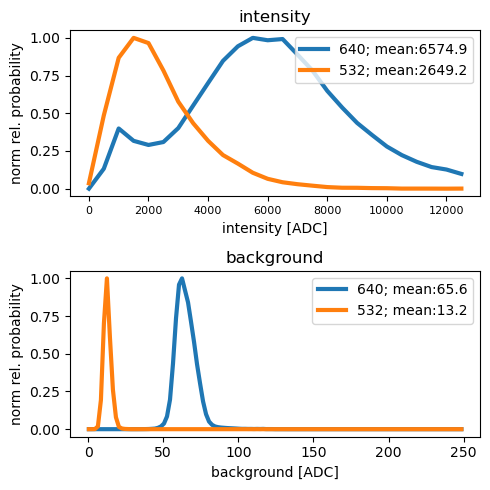

In [145]:
# lateral
base_bin = 500
base_min_bin = 0
base_max_bin = 13000
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(5, 5))

mean_640 = str(np.round(np.mean(dat_640.data.intensity), 1))
mean_532 = str(np.round(np.mean(dat_532.data.intensity), 1))
ax_640_hist, ax_640_bin_edges = calc_bins_norm(base_bin, base_min_bin, base_max_bin, dat_640.data.intensity)
ax_532_hist, ax_532_bin_edges = calc_bins_norm(base_bin, base_min_bin, base_max_bin, dat_532.data.intensity)
axs[0].plot(ax_640_bin_edges, ax_640_hist, label=f"640; mean:{mean_640}", linewidth=3)
axs[0].plot(ax_532_bin_edges, ax_532_hist, label=f"532; mean:{mean_532}", linewidth=3)

base_bin = 2
base_min_bin = 0
base_max_bin = 250
mean_640 = str(np.round(np.mean(dat_640.data.local_background), 1))
mean_532 = str(np.round(np.mean(dat_532.data.local_background), 1))
ax_640_hist, ax_640_bin_edges = calc_bins_norm(base_bin, base_min_bin, base_max_bin, dat_640.data.local_background)
ax_532_hist, ax_532_bin_edges = calc_bins_norm(base_bin, base_min_bin, base_max_bin, dat_532.data.local_background)
axs[1].plot(ax_640_bin_edges, ax_640_hist, label = f"640; mean:{mean_640}", linewidth=3)
axs[1].plot(ax_532_bin_edges, ax_532_hist, label = f"532; mean:{mean_532}", linewidth=3)

axs[0].legend()  #prop={'size': 15})
axs[1].legend()  #prop={'size': 15})
#axs.text()
axs[0].set_title("intensity")
axs[0].set_xlabel("intensity [ADC]")
axs[0].set_ylabel("norm rel. probability")
axs[0].tick_params(axis='x', which='major', labelsize=8)

axs[1].set_title("background")
axs[1].set_xlabel("background [ADC]")
axs[1].set_ylabel("norm rel. probability")
fig.set_tight_layout('tight')

filename = os.path.splitext(loc_file_640)[0] + "_intensity_backgrund_plot.png"
fig.savefig(filename)

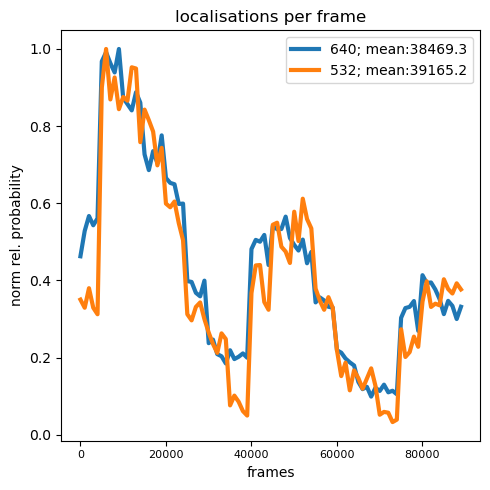

In [146]:
# lateral
base_bin = 1000
base_min_bin = 0
base_max_bin = 90000
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 5))

mean_640 = str(np.round(np.mean(dat_640.data.frame), 1))
mean_532 = str(np.round(np.mean(dat_532.data.frame), 1))
ax_640_hist, ax_640_bin_edges = calc_bins_norm(base_bin, base_min_bin, base_max_bin, dat_640.data.frame)
ax_532_hist, ax_532_bin_edges = calc_bins_norm(base_bin, base_min_bin, base_max_bin, dat_532.data.frame)
axs.plot(ax_640_bin_edges, ax_640_hist, label=f"640; mean:{mean_640}", linewidth=3)
axs.plot(ax_532_bin_edges, ax_532_hist, label=f"532; mean:{mean_532}", linewidth=3)


axs.legend()  #prop={'size': 15})

#axs.text()
axs.set_title("localisations per frame")
axs.set_xlabel("frames")
axs.set_ylabel("norm rel. probability")
axs.tick_params(axis='x', which='major', labelsize=8)


fig.set_tight_layout('tight')

filename = os.path.splitext(loc_file_640)[0] + "_frames_plot.png"
fig.savefig(filename)

# 7. Visualize and Save
## 7.1 Visualization in napari

In [147]:
viewer = napari.Viewer(ndisplay=3)

In [148]:
test = lc.select_by_condition(dat_640_xyz_of_cor, condition=f'0 < position_z < 105_000')
prob_width = 90  # range of point size

coordinates = pd.DataFrame(
    {
        'position_z': test.data.position_z,
        'position_x': test.data.position_x,
        'position_y': test.data.position_y,

    })

colors = test.data.frame.to_numpy()
colors_norm = (colors - np.min(colors)) / (np.max(colors) - np.min(colors))

#prob = dat_640_xyz_cor.data.localization_count.to_numpy()#*111
#prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1
prob = test.data.x_sig.to_numpy()
prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1

point_features = {
    'z_value': colors_norm,
    'prob': (1/prob).tolist(),
}

points = coordinates.to_numpy()

viewer.add_points(points, symbol='o', features=point_features, face_color='prob', face_colormap= 'magenta', border_color='prob', border_colormap='magenta', size=prob_norm, name='640 offset corrected', blending='additive')

<Points layer '640 offset corrected' at 0x1b0cee71810>

In [149]:
test = lc.select_by_condition(dat_532_xyz_of_cor_al, condition=f'0 < position_z < 105_000')
prob_width = 90  # range of point size

coordinates = pd.DataFrame(
    {
        'position_z': test.data.position_z,
        'position_x': test.data.position_x,
        'position_y': test.data.position_y,

    })

colors = test.data.frame.to_numpy()
colors_norm = (colors - np.min(colors)) / (np.max(colors) - np.min(colors))

#prob = dat_640_xyz_cor.data.localization_count.to_numpy()#*111
#prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1
prob = test.data.x_sig.to_numpy()
prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1

point_features = {
    'z_value': colors_norm,
    'prob': (1/prob).tolist(),
}

points = coordinates.to_numpy()

viewer.add_points(points, symbol='o', features=point_features, face_color='prob', face_colormap= 'green', border_color='prob', border_colormap='green', size=prob_norm, name='532 offset corrected', blending='additive')

<Points layer '532 offset corrected' at 0x1b0b8f82c10>

## 7.2 Save corrected files

In [96]:
path_640 = Path(loc_file_640).parent / (Path(loc_file_640).stem + '_drift_aligned.asdf')
path_532 = Path(loc_file_532).parent / (Path(loc_file_532).stem + '_drift_aligned.asdf')
lc.save_asdf(dat_640_xyz_of_cor, path_640)
lc.save_asdf(dat_532_xyz_of_cor_al, path_532)


## 7.3 Scalebar and rotation

In [128]:
viewer.scale_bar.visible = True

# Text options
viewer.scale_bar.unit = 'nm'  # set to None to diplay no unit
viewer.scale_bar.length = 200  # length, in units, of the scale bar
viewer.scale_bar.font_size = 0  # default is 10

# Text color
viewer.scale_bar.colored = True  # default value is False
viewer.scale_bar.color = 'white'  # default value is magenta: (1,0,1,1)

# Background box
viewer.scale_bar.box = False  # add background box, default is False
#viewer.scale_bar.box_color = (0, 1, 1, 0.2)  # cyan with alpha=0.2

# Scale bar position
viewer.scale_bar.position = 'bottom_left'  # default is 'bottom_right'
viewer.scale_bar.ticks = False

In [94]:
viewer.camera.angles

(np.float64(0.0), np.float64(0.0), np.float64(90.00000000000001))

In [95]:
viewer.camera.angles

(np.float64(-1.0722883238981267),
 np.float64(-17.712932272001737),
 np.float64(0.3886986735235733))

In [96]:
viewer.camera.angles = (np.float64(0), np.float64(0), np.float64(0))